# Next-Best-Action Audience Optimization — Contextual Bandits (Hospitality & Resorts)
Self-contained notebook version of the pipeline (the FastAPI serving layer / Playwright screenshots are intentionally excluded).

**Flow:** config → synthetic confounded guest logs → preprocessing → 10 contextual-bandit policies (8 families, CUDA) → off-policy evaluation (DM / IPS / SNIPS / DR) → online replay → plots & artifacts.

Artifacts are written to `output/models`, `output/logs`, `output/plots` (same locations as the scripted pipeline).

## 1. Configuration

In [1]:
"""Central configuration: paths, seeds, device and the discrete action space."""
from pathlib import Path

import numpy as np
import torch

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "output"
MODELS_DIR = OUTPUT_DIR / "models"
LOGS_DIR = OUTPUT_DIR / "logs"
PLOTS_DIR = OUTPUT_DIR / "plots"
SCREENSHOTS_DIR = OUTPUT_DIR / "screenshots"

for _d in (DATA_DIR, MODELS_DIR, LOGS_DIR, PLOTS_DIR, SCREENSHOTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
XGB_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

N_ACTIONS = 6
ACTIONS = {
    0: "Control / No Offer",
    1: "10% Room Rate Discount",
    2: "Complimentary Room Upgrade",
    3: "$50 Dining & Spa Credit",
    4: "Late Checkout + Priority Transfer",
    5: "Double Loyalty Points",
}
ACTION_SHORT = ["Control", "10% Discount", "Room Upgrade", "$50 Dining/Spa", "Late C/O + Transfer", "2x Points"]

# Semantic arm attributes used by the hybrid LinUCB (shared coefficients across arms):
# [price_cut, room_perk, ancillary_perk, convenience, loyalty_perk, any_offer]
ACTION_ATTR = np.array(
    [
        [0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 1],
        [0, 1, 0.3, 0, 0, 1],
        [0, 0, 1, 0, 0, 1],
        [0, 0.4, 0, 1, 0, 1],
        [0, 0, 0.2, 0, 1, 1],
    ],
    dtype=np.float64,
)

# Categorical vocabularies (fixed so the API and the training pipeline agree)
TIERS = ["Bronze", "Silver", "Gold", "Platinum"]
CHANNELS = ["Web", "App", "OTA"]
ARCHETYPES = ["Business", "Family", "Couple", "Solo"]
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# Contribution-margin economics (shared by generator and docs)
ROOM_MARGIN = 0.65
ANC_MARGIN = 0.45


## 2. Telemetry (structured JSONL logging)

In [2]:
"""Structured JSONL telemetry."""
import json
import threading
import time
from pathlib import Path


_lock = threading.Lock()


def _default(o):
    try:
        import numpy as np

        if isinstance(o, np.generic):
            return o.item()
        if isinstance(o, np.ndarray):
            return o.tolist()
    except Exception:  # pragma: no cover
        pass
    return str(o)


def log_jsonl(path, record: dict):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    rec = {"ts": time.strftime("%Y-%m-%dT%H:%M:%S"), **record}
    with _lock, open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec, default=_default) + "\n")


def training_logger(path=None):
    path = Path(path) if path else LOGS_DIR / "training_metrics.jsonl"

    def _log(record: dict):
        log_jsonl(path, record)

    return _log


## 3. Synthetic hospitality data generator
Confounded logging policy (full overlap), non-linear margin-aware reward; ground-truth expected margins are kept for validation only.

In [3]:
"""Synthetic hospitality guest-session generator with logged bandit feedback.

Produces, per session: context X, the logged action A drawn from a *confounded*
logging policy (propensity depends on context), the logged propensity, the realised
net contribution margin R, and (for simulation-only diagnostics) the ground-truth
expected margin of every action (`true_r_a*`) plus the full logging distribution
(`log_p_a*`).  The ground-truth columns must never be used as model inputs.
"""
import numpy as np
import pandas as pd


DISCOUNT = np.array([0.0, 0.10, 0.0, 0.0, 0.0, 0.0])
ANC_MULT = np.array([1.00, 1.00, 1.12, 1.40, 1.05, 1.05])
LOG_EPS = 0.12  # uniform mixing in the logging policy -> min propensity >= 0.02 (overlap)


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def _sample_context(n, rng):
    arch = rng.choice(4, size=n, p=[0.22, 0.28, 0.28, 0.22])  # Business, Family, Couple, Solo
    tier_p = np.array([[.20, .30, .30, .20], [.40, .30, .20, .10], [.35, .30, .20, .15], [.45, .30, .17, .08]])
    tier = (rng.random(n)[:, None] > np.cumsum(tier_p[arch], 1)).sum(1).clip(0, 3)

    p_ota = 0.45 - 0.10 * tier
    p_app = 0.15 + 0.10 * tier
    u = rng.random(n)
    channel = np.where(u < p_ota, 2, np.where(u < p_ota + p_app, 1, 0))  # 0 Web, 1 App, 2 OTA

    med_lead = np.array([8, 50, 35, 20])[arch]
    lead = np.clip(rng.lognormal(np.log(med_lead), 0.6), 0, 365).astype(int)

    los = np.where(arch == 0, 1 + rng.poisson(1.5, n),
          np.where(arch == 1, 3 + rng.poisson(2.5, n),
          np.where(arch == 2, 2 + rng.poisson(2.0, n), 1 + rng.poisson(2.0, n)))).clip(1, 14)
    party = np.where(arch == 0, 1 + (rng.random(n) < 0.1),
            np.where(arch == 1, 3 + rng.poisson(0.8, n),
            np.where(arch == 2, 2, 1))).clip(1, 8)

    peak = np.array([3, 3, 3, 1.2, 1, 1.2, 3, 3, 1, 1, 1.2, 3.5], dtype=float)  # month weights
    month = rng.choice(np.arange(1, 13), size=n, p=peak / peak.sum())
    dow_w = np.array([[1.4, 1.4, 1.4, 1.3, .6, .4, .4],      # Business: weekdays
                      [.7, .7, .8, 1, 1.4, 1.5, 1],          # Family
                      [.6, .6, .7, 1, 1.6, 1.6, 1],          # Couple
                      [1, 1, 1, 1, 1, 1, 1]])                # Solo
    dow_p = dow_w[arch] / dow_w[arch].sum(1, keepdims=True)
    dow = (rng.random(n)[:, None] > np.cumsum(dow_p, 1)).sum(1).clip(0, 6)

    hist_spend = np.exp(rng.normal(5.5 + 0.5 * tier + 0.2 * (arch == 1), 0.6)).round(2)
    anc_rate = np.clip(rng.beta(2 + 0.5 * tier, 5 - 0.5 * tier) + 0.08 * (arch == 1) + 0.06 * (arch == 2), 0, 1).round(3)
    return dict(arch=arch, tier=tier, channel=channel, lead=lead, los=los, party=party,
                month=month, dow=dow, hist_spend=hist_spend, anc_rate=anc_rate)


def _economics(c):
    """Return expected margin matrix (n,K), conversion prob matrix, room revenue, ancillary means."""
    n = len(c["tier"])
    tier, arch, ch, lead, los, party = c["tier"], c["arch"], c["channel"], c["lead"], c["los"], c["party"]
    month, dow, anc_rate = c["month"], c["dow"], c["anc_rate"]
    ota, app = (ch == 2).astype(float), (ch == 1).astype(float)
    business, family, couple, solo = [(arch == i).astype(float) for i in range(4)]

    season = np.where(np.isin(month, [12, 1, 2, 3, 7, 8]), 1.30, np.where(np.isin(month, [5, 6, 9, 10]), 0.85, 1.0))
    adr = 260 * season * np.array([1, 1.05, 1.12, 1.25])[tier] * np.array([.95, 1.05, 1.15, .85])[arch] \
        * np.where(dow >= 4, 1.10, 1.0)
    room_rev = adr * los
    anc_base = 30 + 110 * anc_rate * np.sqrt(party) * np.sqrt(los)

    z0 = (-0.55 + 0.30 * tier + 0.5 * app - 0.35 * ota
          + 0.7 * business * (lead < 14) + 0.5 * np.tanh((anc_rate - 0.3) * 4)
          - 0.45 * np.minimum(room_rev / 1500.0, 2.5) + 0.25 * family * (lead > 30))

    peak = np.isin(month, [12, 1, 2, 3, 7, 8]).astype(float)
    price_sens = 0.8 * ota + 0.5 * (tier == 0) + 0.3 * solo + 0.2 * (tier == 1)
    uplift = np.zeros((n, N_ACTIONS))
    uplift[:, 1] = 0.15 + 1.0 * price_sens - 0.5 * (tier == 3) - 0.35 * peak
    uplift[:, 2] = 0.10 + 0.7 * couple + 0.5 * (tier >= 2) + 0.35 * (los >= 4) + 0.2 * peak
    uplift[:, 3] = 0.15 + 0.7 * family + 0.5 * couple * (anc_rate > 0.3) + 0.3 * (party >= 3)
    uplift[:, 4] = 0.05 + 1.0 * business + 0.4 * (lead < 7) + 0.3 * app
    uplift[:, 5] = 0.00 + 0.8 * (tier == 3) + 0.4 * (tier == 2) + 0.3 * app + 0.25 * business
    p_conv = _sigmoid(z0[:, None] + uplift)

    cost = np.zeros((n, N_ACTIONS))
    cost[:, 2] = 60 + 15 * los
    cost[:, 3] = 50 * (0.5 + 0.5 * anc_rate)
    cost[:, 4] = 40 + 3 * party
    cost[:, 5] = 0.02 * room_rev
    anc_mean = anc_base[:, None] * ANC_MULT[None, :]
    room_margin = ROOM_MARGIN * room_rev[:, None] * (1 - DISCOUNT[None, :])
    cond_margin = room_margin + ANC_MARGIN * anc_mean - cost  # margin given conversion
    return p_conv * cond_margin, p_conv, room_margin, anc_mean, cost


def _logging_policy(c):
    n = len(c["tier"])
    tier, arch, ch, lead, anc = c["tier"], c["arch"], c["channel"], c["lead"], c["anc_rate"]
    lg = np.zeros((n, N_ACTIONS))
    lg[:, 0] = 0.6
    lg[:, 1] = 0.9 * (ch == 2) + 0.7 * (tier <= 1) + 0.3 * (lead > 60)
    lg[:, 2] = 0.9 * (tier >= 2) + 0.4 * (arch == 2)
    lg[:, 3] = 0.7 * (arch == 1) + 0.3 * (anc > 0.3)
    lg[:, 4] = 0.8 * (arch == 0) + 0.2 * (lead < 7)
    lg[:, 5] = 0.6 * (tier == 3) + 0.3 * (ch == 1)
    e = np.exp(lg - lg.max(1, keepdims=True))
    sm = e / e.sum(1, keepdims=True)
    return (1 - LOG_EPS) * sm + LOG_EPS / N_ACTIONS


def generate_dataset(n=30000, seed=SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    c = _sample_context(n, rng)
    exp_margin, p_conv, room_margin, anc_mean, cost = _economics(c)
    logp = _logging_policy(c)
    a = (rng.random(n)[:, None] > np.cumsum(logp, 1)).sum(1).clip(0, N_ACTIONS - 1)
    idx = np.arange(n)

    conv = rng.random(n) < p_conv[idx, a]
    room_noise = np.exp(rng.normal(-0.5 * 0.15 ** 2, 0.15, n))
    anc_noise = np.exp(rng.normal(-0.5 * 0.5 ** 2, 0.5, n))
    realised = room_margin[idx, a] * room_noise + ANC_MARGIN * anc_mean[idx, a] * anc_noise - cost[idx, a]
    reward = np.where(conv, realised, 0.0)

    df = pd.DataFrame({
        "loyalty_tier": np.array(TIERS)[c["tier"]],
        "lead_time": c["lead"],
        "los": c["los"],
        "booking_channel": np.array(CHANNELS)[c["channel"]],
        "hist_spend": c["hist_spend"],
        "ancillary_rate": c["anc_rate"],
        "month": c["month"],
        "day_of_week": np.array(DAYS)[c["dow"]],
        "party_size": c["party"],
        "guest_archetype": np.array(ARCHETYPES)[c["arch"]],
        "action": a,
        "propensity": logp[idx, a],
        "converted": conv.astype(int),
        "reward": reward,
    })
    for k in range(N_ACTIONS):
        df[f"true_r_a{k}"] = exp_margin[:, k]
    for k in range(N_ACTIONS):
        df[f"log_p_a{k}"] = logp[:, k]
    return df


def true_reward_matrix(df):
    return df[[f"true_r_a{k}" for k in range(N_ACTIONS)]].to_numpy()


def logging_prob_matrix(df):
    return df[[f"log_p_a{k}" for k in range(N_ACTIONS)]].to_numpy()


## 4. Preprocessing (ColumnTransformer)

In [4]:
"""Feature engineering + ColumnTransformer shared by training and serving."""
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


NUM_COLS = ["log_lead_time", "los", "log_hist_spend", "ancillary_rate", "party_size", "month_sin", "month_cos"]
CAT_COLS = ["loyalty_tier", "booking_channel", "guest_archetype", "day_of_week"]
RAW_COLS = ["loyalty_tier", "lead_time", "los", "booking_channel", "hist_spend", "ancillary_rate",
            "month", "day_of_week", "party_size", "guest_archetype"]


def add_derived(df: pd.DataFrame) -> pd.DataFrame:
    out = df[RAW_COLS].copy()
    out["log_lead_time"] = np.log1p(out["lead_time"].astype(float))
    out["log_hist_spend"] = np.log1p(out["hist_spend"].astype(float))
    ang = 2 * np.pi * out["month"].astype(float) / 12.0
    out["month_sin"] = np.sin(ang)
    out["month_cos"] = np.cos(ang)
    return out


def build_preprocessor() -> ColumnTransformer:
    return ColumnTransformer(
        [("num", StandardScaler(), NUM_COLS),
         ("cat", OneHotEncoder(categories=[TIERS, CHANNELS, ARCHETYPES, DAYS], sparse_output=False,
                               handle_unknown="ignore"), CAT_COLS)],
        verbose_feature_names_out=False,
    )


def feature_names(pre: ColumnTransformer):
    return list(pre.get_feature_names_out())


def transform(pre, df: pd.DataFrame) -> np.ndarray:
    return pre.transform(add_derived(df)).astype(np.float32)


def save_preprocessor(pre, path):
    joblib.dump(pre, path)


def load_preprocessor(path):
    return joblib.load(path)


def fit_preprocessor(df: pd.DataFrame) -> ColumnTransformer:
    pre = build_preprocessor()
    pre.fit(add_derived(df))
    return pre


## 5. Bandit base class

In [5]:
"""Common interface for all contextual bandit policies.

Conventions
-----------
* Constructors are ``Model(n_features, n_actions=6, name=None, **hyperparams)``.
* Rewards are standardised internally (``r_scale``); public ``mean_scores`` are in $ units.
* ``fit`` = offline batch learning from logged bandit feedback (X, a, r, p).
* ``update`` = incremental learning (buffer + warm refit) used by the online replay and the API.
* ``select_action`` = the *acting* policy (exploration included); ``action_probs`` = its action
  distribution (Monte-Carlo for stochastic policies) used by off-policy evaluation.
"""
import time
from pathlib import Path

import joblib
import numpy as np


class BaseBandit:
    DEFAULTS: dict = {}
    stochastic = False
    default_name = None

    def __init__(self, n_features, n_actions=6, name=None, **hp):
        self.d = int(n_features)
        self.K = int(n_actions)
        self.hp = {**self.DEFAULTS, **hp}
        self.name = name or self.default_name or type(self).__name__
        self.epsilon = float(self.hp.get("epsilon", 0.0))
        self.update_every = int(self.hp.get("update_every", 1))
        self.r_scale = 1.0
        self.fitted = False
        self._buf = None
        self._rounds = 0
        self.logger = None
        self.feature_names = None
        self.rng = np.random.default_rng(int(self.hp.get("seed", 0)))

    # ------------------------------------------------------------------ hooks
    def _fit(self, X, a, r, p, warm=False):
        raise NotImplementedError

    def _mean(self, X) -> np.ndarray:
        raise NotImplementedError

    def _acting(self, X) -> np.ndarray:
        return self._mean(X)

    def _save_weights(self, stem: Path):
        raise NotImplementedError

    def _load_weights(self, stem: Path):
        raise NotImplementedError

    # --------------------------------------------------------------- utilities
    def _log(self, **rec):
        if self.logger is not None:
            self.logger({"model": self.name, **rec})

    @staticmethod
    def _prep(X, a, r, p, K):
        X = np.ascontiguousarray(X, dtype=np.float32)
        a = np.asarray(a, dtype=np.int64)
        r = np.asarray(r, dtype=np.float64)
        p = np.full(len(a), 1.0 / K) if p is None else np.asarray(p, dtype=np.float64)
        return X, a, r, p

    # ---------------------------------------------------------------- learning
    def fit(self, X, a, r, p=None):
        X, a, r, p = self._prep(X, a, r, p, self.K)
        self.r_scale = float(max(r.std(), 1e-3))
        self._buf = [X, a, r, p]
        t0 = time.time()
        self._fit(X, a, r / self.r_scale, p, warm=False)
        self.fitted = True
        self._log(event="fit_done", n=len(a), seconds=round(time.time() - t0, 3))
        return self

    def update(self, X, a, r, p=None):
        X, a, r, p = self._prep(X, a, r, p, self.K)
        if self._buf is None:
            self._buf = [X, a, r, p]
            self.r_scale = float(max(r.std(), 1e-3))
        else:
            self._buf = [np.concatenate([o, n]) for o, n in zip(self._buf, (X, a, r, p))]
        self._rounds += 1
        if (not self.fitted) or self._rounds % self.update_every == 0:
            Xb, ab, rb, pb = self._buf
            self._fit(Xb, ab, rb / self.r_scale, pb, warm=self.fitted)
            self.fitted = True
        return self

    # --------------------------------------------------------------- inference
    def mean_scores(self, X):
        """Estimated expected net margin ($) per action, shape (n, K)."""
        return self._mean(np.ascontiguousarray(X, dtype=np.float32)) * self.r_scale

    def acting_scores(self, X):
        return self._acting(np.ascontiguousarray(X, dtype=np.float32)) * self.r_scale

    def select_action(self, X):
        X = np.ascontiguousarray(X, dtype=np.float32)
        n = len(X)
        if not self.fitted:
            return self.rng.integers(0, self.K, n)
        a = self._acting(X).argmax(1)
        if self.epsilon > 0:
            m = self.rng.random(n) < self.epsilon
            a[m] = self.rng.integers(0, self.K, int(m.sum()))
        return a

    def action_probs(self, X, n_mc=40):
        X = np.ascontiguousarray(X, dtype=np.float32)
        n = len(X)
        if not self.fitted:
            return np.full((n, self.K), 1.0 / self.K)
        if self.stochastic:
            probs = np.zeros((n, self.K))
            for _ in range(n_mc):
                probs[np.arange(n), self._acting(X).argmax(1)] += 1.0
            probs /= n_mc
        else:
            probs = np.zeros((n, self.K))
            probs[np.arange(n), self._acting(X).argmax(1)] = 1.0
        if self.epsilon > 0:
            probs = (1 - self.epsilon) * probs + self.epsilon / self.K
        return probs

    # ------------------------------------------------------------- persistence
    def save(self, out_dir):
        out_dir = Path(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)
        joblib.dump({"cls": type(self).__name__, "name": self.name, "d": self.d, "K": self.K, "hp": self.hp,
                     "r_scale": self.r_scale, "feature_names": self.feature_names}, out_dir / f"{self.name}.meta.joblib")
        if self._buf is not None:
            X, a, r, p = self._buf
            np.savez_compressed(out_dir / f"{self.name}.buffer.npz", X=X, a=a, r=r, p=p)
        self._save_weights(out_dir / self.name)

    def _restore(self, meta, out_dir):
        self.r_scale = meta["r_scale"]
        self.feature_names = meta.get("feature_names")
        stem = Path(out_dir) / self.name
        self._load_weights(stem)
        buf = Path(out_dir) / f"{self.name}.buffer.npz"
        if buf.exists():
            z = np.load(buf)
            self._buf = [z["X"], z["a"], z["r"], z["p"]]
        self.fitted = True
        return self


## 6. Linear bandits — LinUCB (disjoint + hybrid), Linear Thompson Sampling

In [6]:
"""Linear contextual bandits: LinUCB (disjoint + hybrid) and Linear Thompson Sampling (GPU, float64)."""
from pathlib import Path

import numpy as np
import torch



def aug(X):
    return np.hstack([X, np.ones((len(X), 1), np.float32)])


def arm_stats(Phi, a, r, K, lam=1.0, device=DEVICE):
    """Per-arm ridge posterior. Returns Ainv (K,D,D), mu (K,D), sigma (K,) [float64, on device]."""
    P = torch.as_tensor(Phi, dtype=torch.float64, device=device)
    at = torch.as_tensor(a, device=device)
    rt = torch.as_tensor(r, dtype=torch.float64, device=device)
    D = P.shape[1]
    I = torch.eye(D, dtype=torch.float64, device=device)
    Ainv = torch.empty(K, D, D, dtype=torch.float64, device=device)
    mu = torch.zeros(K, D, dtype=torch.float64, device=device)
    sig = torch.ones(K, dtype=torch.float64, device=device)
    for k in range(K):
        m = at == k
        Xk, rk = P[m], rt[m]
        Ai = torch.linalg.inv(lam * I + Xk.T @ Xk)
        Ainv[k] = Ai
        if len(rk):
            mu[k] = Ai @ (Xk.T @ rk)
            res = rk - Xk @ mu[k]
            sig[k] = torch.sqrt(torch.clamp((res ** 2).mean(), min=1e-3))
    return Ainv, mu, sig


class ArmPosterior:
    """Bayesian linear posterior per arm with batched Thompson sampling."""

    def __init__(self, Ainv, mu, sig):
        self.Ainv, self.mu, self.sig = Ainv, mu, sig
        sym = 0.5 * (Ainv + Ainv.transpose(1, 2)) + 1e-9 * torch.eye(Ainv.shape[1], dtype=Ainv.dtype, device=Ainv.device)
        self.L = torch.linalg.cholesky(sym).float()
        self.mu32, self.sig32 = mu.float(), sig.float()

    def mean(self, Phi_t):
        return Phi_t @ self.mu32.T

    def sample_scores(self, Phi_t, v=1.0, chunk=4096):
        K, D = self.mu32.shape
        out = []
        for i in range(0, len(Phi_t), chunk):
            P = Phi_t[i:i + chunk]
            eps = torch.randn(len(P), K, D, device=P.device)
            theta = self.mu32[None] + v * self.sig32[None, :, None] * torch.einsum("ked,nkd->nke", self.L, eps)
            out.append(torch.einsum("nd,nkd->nk", P, theta))
        return torch.cat(out)

    def state(self):
        return {"Ainv": self.Ainv.cpu().numpy(), "mu": self.mu.cpu().numpy(), "sig": self.sig.cpu().numpy()}

    @classmethod
    def from_state(cls, s):
        t = lambda k: torch.as_tensor(s[k], dtype=torch.float64, device=DEVICE)
        return cls(t("Ainv"), t("mu"), t("sig"))


class LinUCB(BaseBandit):
    """Disjoint / hybrid LinUCB (Li et al., 2010) with exact batch ridge solutions on GPU."""
    DEFAULTS = dict(alpha=0.3, lam=1.0, hybrid=False)

    def __init__(self, n_features, n_actions=6, name=None, **hp):
        hybrid = hp.get("hybrid", False)
        super().__init__(n_features, n_actions, name or ("LinUCB-Hybrid" if hybrid else "LinUCB-Disjoint"), **hp)
        self.state = None

    def _fit(self, X, a, r, p, warm=False):
        lam, K = self.hp["lam"], self.K
        Phi = aug(X)
        if not self.hp["hybrid"]:
            Ainv, mu, _ = arm_stats(Phi, a, r, K, lam)
            self.state = {"Ainv": Ainv, "mu": mu}
            return
        dev = DEVICE
        P = torch.as_tensor(Phi, dtype=torch.float64, device=dev)
        at = torch.as_tensor(a, device=dev)
        rt = torch.as_tensor(r, dtype=torch.float64, device=dev)
        attr = torch.as_tensor(ACTION_ATTR, dtype=torch.float64, device=dev)
        D, m = P.shape[1], attr.shape[1]
        kd = D * m
        I, Ik = torch.eye(D, dtype=torch.float64, device=dev), torch.eye(kd, dtype=torch.float64, device=dev)
        A0, b0 = lam * Ik.clone(), torch.zeros(kd, dtype=torch.float64, device=dev)
        per = []
        for k in range(K):
            msk = at == k
            Xk, rk = P[msk], rt[msk]
            Zk = (Xk[:, :, None] * attr[k][None, None, :]).reshape(len(Xk), kd)
            Aik = torch.linalg.inv(lam * I + Xk.T @ Xk)
            Bk, bk = Xk.T @ Zk, Xk.T @ rk
            A0 = A0 + Zk.T @ Zk - Bk.T @ Aik @ Bk
            b0 = b0 + Zk.T @ rk - Bk.T @ Aik @ bk
            per.append((Aik, Bk, bk))
        A0inv = torch.linalg.inv(A0)
        beta = A0inv @ b0
        self.state = {
            "beta": beta, "A0inv": A0inv,
            "Ainv": torch.stack([p_[0] for p_ in per]),
            "B": torch.stack([p_[1] for p_ in per]),
            "mu": torch.stack([p_[0] @ (p_[2] - p_[1] @ beta) for p_ in per]),
        }

    @torch.no_grad()
    def _predict(self, X):
        P = torch.as_tensor(aug(X), dtype=torch.float64, device=DEVICE)
        s = self.state
        mean = P @ s["mu"].T
        var = torch.einsum("nd,kde,ne->nk", P, s["Ainv"], P)
        if self.hp["hybrid"]:
            attr = torch.as_tensor(ACTION_ATTR, dtype=torch.float64, device=DEVICE)
            n, D = P.shape
            for k in range(self.K):
                z = (P[:, :, None] * attr[k][None, None, :]).reshape(n, -1)
                u = P @ s["Ainv"][k]                      # (n,D) = xᵀAk⁻¹
                w = u @ s["B"][k]                         # (n,kd) = xᵀAk⁻¹Bk
                zA = z @ s["A0inv"]
                mean[:, k] += z @ s["beta"]
                var[:, k] = ((zA * z).sum(1) - 2 * (zA * w).sum(1) + (P * u).sum(1) + ((w @ s["A0inv"]) * w).sum(1))
        return mean, var.clamp_min(0)

    def _mean(self, X):
        return self._predict(X)[0].float().cpu().numpy()

    def _acting(self, X):
        mean, var = self._predict(X)
        return (mean + self.hp["alpha"] * var.sqrt()).float().cpu().numpy()

    def _save_weights(self, stem):
        np.savez_compressed(f"{stem}.npz", **{k: v.cpu().numpy() for k, v in self.state.items()})

    def _load_weights(self, stem):
        z = np.load(f"{stem}.npz")
        self.state = {k: torch.as_tensor(z[k], dtype=torch.float64, device=DEVICE) for k in z.files}


class LinearThompsonSampling(BaseBandit):
    """Bayesian linear regression per arm; acts on a joint posterior sample theta_a ~ N(mu_a, v^2 s_a^2 A_a^-1)."""
    DEFAULTS = dict(v=1.0, lam=1.0)
    stochastic = True
    default_name = "LinearTS"

    def _fit(self, X, a, r, p, warm=False):
        self.post = ArmPosterior(*arm_stats(aug(X), a, r, self.K, self.hp["lam"]))

    def _phi(self, X):
        return torch.as_tensor(aug(X), device=DEVICE)

    @torch.no_grad()
    def _mean(self, X):
        return self.post.mean(self._phi(X)).cpu().numpy()

    @torch.no_grad()
    def _acting(self, X):
        return self.post.sample_scores(self._phi(X), self.hp["v"]).cpu().numpy()

    def _save_weights(self, stem):
        np.savez_compressed(f"{stem}.npz", **self.post.state())

    def _load_weights(self, stem):
        self.post = ArmPosterior.from_state(np.load(f"{stem}.npz"))


## 7. Tree bandits — XGBoost ε-greedy & UCB (GPU)

In [7]:
"""Gradient-boosted-tree contextual bandits (XGBoost on GPU)."""
from pathlib import Path

import numpy as np
import xgboost as xgb



class _XGBBandit(BaseBandit):
    """One boosted regressor family on [x, onehot(a)]; ``n_models`` bootstrap members give uncertainty."""
    DEFAULTS = dict(n_models=1, n_estimators=300, max_depth=6, lr=0.08, subsample=0.8, colsample=0.8,
                    epsilon=0.0, beta=0.0, update_every=3, seed=0)

    def _make(self, i):
        return xgb.XGBRegressor(
            n_estimators=self.hp["n_estimators"], max_depth=self.hp["max_depth"], learning_rate=self.hp["lr"],
            subsample=self.hp["subsample"], colsample_bytree=self.hp["colsample"], tree_method="hist",
            device=XGB_DEVICE, random_state=self.hp["seed"] + i, reg_lambda=2.0, min_child_weight=5,
            eval_metric="rmse", verbosity=0)

    def _design(self, X, a):
        return np.hstack([X, np.eye(self.K, dtype=np.float32)[a]])

    def _fit(self, X, a, r, p, warm=False):
        n = len(a)
        rng = np.random.default_rng(self.hp["seed"] + self._rounds)
        perm = rng.permutation(n)
        n_val = max(int(0.1 * n), 1)
        val, tr = perm[:n_val], perm[n_val:]
        Zv, rv = self._design(X[val], a[val]), r[val]
        self.models = []
        for i in range(self.hp["n_models"]):
            idx = tr if self.hp["n_models"] == 1 else rng.choice(tr, size=len(tr), replace=True)
            m = self._make(i)
            m.fit(self._design(X[idx], a[idx]), r[idx], eval_set=[(self._design(X[idx], a[idx]), r[idx]), (Zv, rv)],
                  verbose=False)
            if i == 0:
                ev = m.evals_result()
                for t, (tl, vl) in enumerate(zip(ev["validation_0"]["rmse"], ev["validation_1"]["rmse"])):
                    if t % 5 == 0 or t == len(ev["validation_0"]["rmse"]) - 1:
                        self._log(event="epoch", epoch=t + 1, train_loss=tl, val_loss=vl, metric="rmse(scaled $)",
                                  kind="boost_round")
            self.models.append(m)

    def _member_preds(self, X):
        n = len(X)
        Z = np.hstack([np.repeat(X, self.K, axis=0), np.tile(np.eye(self.K, dtype=np.float32), (n, 1))])
        return np.stack([m.predict(Z).reshape(n, self.K) for m in self.models])  # (M,n,K)

    def _mean(self, X):
        return self._member_preds(X).mean(0)

    def _acting(self, X):
        P = self._member_preds(X)
        if self.hp["beta"] > 0 and len(self.models) > 1:
            return P.mean(0) + self.hp["beta"] * P.std(0)
        return P.mean(0)

    def feature_importance(self):
        """Mean gain importance per input feature, aggregated over members and actions."""
        names = (self.feature_names or [f"f{i}" for i in range(self.d)])
        gains = np.zeros(self.d)
        for m in self.models:
            sc = m.get_booster().get_score(importance_type="gain")
            for k, v in sc.items():
                j = int(k[1:])
                if j < self.d:
                    gains[j] += v / len(self.models)
        return dict(zip(names, gains))

    def _save_weights(self, stem):
        for i, m in enumerate(self.models):
            m.save_model(f"{stem}.m{i}.json")

    def _load_weights(self, stem):
        self.models = []
        for i in range(self.hp["n_models"]):
            m = self._make(i)
            m.load_model(f"{stem}.m{i}.json")
            self.models.append(m)


class XGBoostEpsilonGreedy(_XGBBandit):
    default_name = "XGBoost-EpsGreedy"
    DEFAULTS = {**_XGBBandit.DEFAULTS, "n_models": 1, "epsilon": 0.05}


class XGBoostUCB(_XGBBandit):
    """Bootstrapped-ensemble UCB: mean + beta * std across members (GPU-trained)."""
    default_name = "XGBoost-UCB"
    DEFAULTS = {**_XGBBandit.DEFAULTS, "n_models": 8, "beta": 1.0, "n_estimators": 200}


## 8. Neural bandits — NeuralEpsGreedy, NeuralLinear, NeuralTS, NeuralUCB (PyTorch GPU)

In [8]:
"""Deep neural contextual bandits on GPU: NeuralEpsilonGreedy, NeuralLinear, NeuralTS, NeuralUCB."""
import copy

import numpy as np
import torch
import torch.nn as nn
from torch.func import functional_call, jacrev, vmap



class QNet(nn.Module):
    """MLP with BatchNorm + Dropout and K output heads (one reward estimate per action)."""

    def __init__(self, d, K, hidden=(128, 64), dropout=0.1):
        super().__init__()
        layers, prev = [], d
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        self.trunk = nn.Sequential(*layers)
        self.head = nn.Linear(prev, K)
        self.out_dim = prev

    def features(self, x):
        return self.trunk(x)

    def forward(self, x):
        return self.head(self.trunk(x))


def make_qnet(d, K, hp):
    return QNet(d, K, tuple(hp["hidden"]), hp["dropout"]).to(DEVICE)


def train_qnet(net, X, a, r, *, epochs, lr, wd, bs, val_frac=0.1, log=None, tag="", seed=0):
    """Masked-MSE regression on the logged action's reward. Keeps best-val weights when val_frac > 0."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    n = len(a)
    Xt = torch.as_tensor(X, device=DEVICE)
    at = torch.as_tensor(a, device=DEVICE)
    rt = torch.as_tensor(r, dtype=torch.float32, device=DEVICE)
    perm = torch.randperm(n, generator=g).to(DEVICE)
    nv = int(val_frac * n) if val_frac > 0 else 0
    vi, ti = perm[:nv], perm[nv:]
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    best, best_state = float("inf"), None
    for ep in range(epochs):
        net.train()
        sh = ti[torch.randperm(len(ti), generator=g).to(DEVICE)]
        tot, cnt = 0.0, 0
        for i in range(0, len(sh), bs):
            b = sh[i:i + bs]
            if len(b) < 2:
                continue
            pred = net(Xt[b]).gather(1, at[b, None]).squeeze(1)
            loss = ((pred - rt[b]) ** 2).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 5.0)
            opt.step()
            tot += loss.item() * len(b)
            cnt += len(b)
        rec = {"event": "epoch", "tag": tag, "epoch": ep + 1, "train_loss": tot / max(cnt, 1), "kind": "epoch"}
        if nv:
            net.eval()
            with torch.no_grad():
                vl = ((net(Xt[vi]).gather(1, at[vi, None]).squeeze(1) - rt[vi]) ** 2).mean().item()
            rec["val_loss"] = vl
            if vl < best:
                best, best_state = vl, copy.deepcopy(net.state_dict())
        if log:
            log(rec)
    if best_state is not None:
        net.load_state_dict(best_state)
    net.eval()
    return net


@torch.no_grad()
def predict_net(net, X, chunk=8192, mc_dropout=False):
    net.train(mc_dropout)
    if mc_dropout:  # keep BN in eval mode, only dropout stochastic
        for m in net.modules():
            if isinstance(m, nn.BatchNorm1d):
                m.eval()
    out = []
    for i in range(0, len(X), chunk):
        out.append(net(torch.as_tensor(X[i:i + chunk], device=DEVICE)))
    net.eval()
    return torch.cat(out)


@torch.no_grad()
def net_features(net, X, chunk=8192):
    net.eval()
    return torch.cat([net.features(torch.as_tensor(X[i:i + chunk], device=DEVICE)) for i in range(0, len(X), chunk)])


NEURAL_DEFAULTS = dict(hidden=(128, 64), dropout=0.1, epochs=40, replay_epochs=3, lr=2e-3, wd=1e-4, bs=512,
                       epsilon=0.0, seed=0)


class _NeuralBase(BaseBandit):
    DEFAULTS = NEURAL_DEFAULTS

    def _train(self, net, X, a, r, warm, tag=""):
        ep = self.hp["replay_epochs"] if warm else self.hp["epochs"]
        return train_qnet(net, X, a, r, epochs=ep, lr=self.hp["lr"] * (0.5 if warm else 1.0), wd=self.hp["wd"],
                          bs=self.hp["bs"], val_frac=0.0 if warm else 0.1, log=(lambda rec: self._log(**rec)) if self.logger else None,
                          tag=tag, seed=self.hp["seed"] + self._rounds)


class NeuralEpsilonGreedy(_NeuralBase):
    default_name = "NeuralEpsGreedy"
    DEFAULTS = {**NEURAL_DEFAULTS, "epsilon": 0.05}

    def __init__(self, *a, **k):
        super().__init__(*a, **k)
        self.net = None

    def _fit(self, X, a, r, p, warm=False):
        if self.net is None or not warm:
            torch.manual_seed(self.hp["seed"])
            self.net = make_qnet(self.d, self.K, self.hp)
        self._train(self.net, X, a, r, warm and self.net is not None)

    def _mean(self, X):
        return predict_net(self.net, X).cpu().numpy()

    def _save_weights(self, stem):
        torch.save({"net": self.net.state_dict()}, f"{stem}.pt")

    def _load_weights(self, stem):
        self.net = make_qnet(self.d, self.K, self.hp)
        self.net.load_state_dict(torch.load(f"{stem}.pt", map_location=DEVICE, weights_only=False)["net"])
        self.net.eval()


class NeuralLinearBandit(_NeuralBase):
    """Deep representation learning + exact Bayesian linear last layer (Riquelme et al., 2018)."""
    default_name = "NeuralLinear"
    stochastic = True
    DEFAULTS = {**NEURAL_DEFAULTS, "v": 1.0, "lam": 1.0}

    def __init__(self, *a, **k):
        super().__init__(*a, **k)
        self.net, self.post = None, None

    def _phi(self, X):
        f = net_features(self.net, X)
        return torch.cat([f, torch.ones(len(f), 1, device=f.device)], 1)

    def _fit(self, X, a, r, p, warm=False):
        if self.net is None or not warm:
            torch.manual_seed(self.hp["seed"])
            self.net = make_qnet(self.d, self.K, self.hp)
        self._train(self.net, X, a, r, warm and self.net is not None)
        Phi = self._phi(X).double().cpu().numpy()
        self.post = ArmPosterior(*arm_stats(Phi, a, r, self.K, self.hp["lam"]))

    @torch.no_grad()
    def _mean(self, X):
        return self.post.mean(self._phi(X)).cpu().numpy()

    @torch.no_grad()
    def _acting(self, X):
        return self.post.sample_scores(self._phi(X), self.hp["v"]).cpu().numpy()

    def _save_weights(self, stem):
        torch.save({"net": self.net.state_dict(), "post": self.post.state()}, f"{stem}.pt")

    def _load_weights(self, stem):
        z = torch.load(f"{stem}.pt", map_location=DEVICE, weights_only=False)
        self.net = make_qnet(self.d, self.K, self.hp)
        self.net.load_state_dict(z["net"])
        self.net.eval()
        self.post = ArmPosterior.from_state(z["post"])


class NeuralTS(_NeuralBase):
    """Thompson sampling from a deep ensemble whose members use MC-Dropout at decision time."""
    default_name = "NeuralTS"
    stochastic = True
    DEFAULTS = {**NEURAL_DEFAULTS, "n_members": 5, "dropout": 0.15, "epochs": 30}

    def __init__(self, *a, **k):
        super().__init__(*a, **k)
        self.nets = None

    def _fit(self, X, a, r, p, warm=False):
        if self.nets is None or not warm:
            self.nets = []
            for m in range(self.hp["n_members"]):
                torch.manual_seed(self.hp["seed"] + 100 * m)
                self.nets.append(make_qnet(self.d, self.K, self.hp))
        for m, net in enumerate(self.nets):
            self._train(net, X, a, r, warm, tag=f"member{m}" if m == 0 else f"member{m}")

    @torch.no_grad()
    def _mean(self, X):
        return torch.stack([predict_net(n, X) for n in self.nets]).mean(0).cpu().numpy()

    @torch.no_grad()
    def _acting(self, X):
        outs = torch.stack([predict_net(n, X, mc_dropout=True) for n in self.nets])  # (M,n,K)
        idx = torch.randint(0, len(self.nets), (outs.shape[1],), device=outs.device)
        return outs[idx, torch.arange(outs.shape[1], device=outs.device)].cpu().numpy()

    def _save_weights(self, stem):
        torch.save({"nets": [n.state_dict() for n in self.nets]}, f"{stem}.pt")

    def _load_weights(self, stem):
        z = torch.load(f"{stem}.pt", map_location=DEVICE, weights_only=False)
        self.nets = []
        for sd in z["nets"]:
            n = make_qnet(self.d, self.K, self.hp)
            n.load_state_dict(sd)
            n.eval()
            self.nets.append(n)


class NeuralUCB(_NeuralBase):
    """UCB with gradient-based confidence bounds (Zhou et al., 2020) using a diagonal Fisher/NTK approximation
    over the last hidden layer and output head: bonus(x,a) = alpha * sqrt( sum_p g_p(x,a)^2 / Z_p )."""
    default_name = "NeuralUCB"
    DEFAULTS = {**NEURAL_DEFAULTS, "alpha": 0.05, "lam": 1.0}

    def __init__(self, *a, **k):
        super().__init__(*a, **k)
        self.net, self.Z = None, None

    # parameters whose gradients define the confidence ellipsoid
    def _sub_names(self):
        last_lin = max(i for i, m in enumerate(self.net.trunk) if isinstance(m, nn.Linear))
        return [f"trunk.{last_lin}.weight", f"trunk.{last_lin}.bias", "head.weight", "head.bias"]

    def _jac(self, Xc):
        names = self._sub_names()
        params = {n: p.detach() for n, p in self.net.named_parameters() if n in names}
        frozen = {n: p.detach() for n, p in self.net.named_parameters() if n not in names}
        buffers = dict(self.net.named_buffers())

        def f(prm, x):
            return functional_call(self.net, ({**prm, **frozen}, buffers), (x.unsqueeze(0),)).squeeze(0)

        J = vmap(jacrev(f), in_dims=(None, 0))(params, Xc)
        return torch.cat([J[n].reshape(len(Xc), self.K, -1) for n in names], dim=2)  # (n,K,P)

    def _build_Z(self, X, a):
        self.net.eval()
        Z = None
        Xt = torch.as_tensor(X, device=DEVICE)
        at = torch.as_tensor(a, device=DEVICE)
        for i in range(0, len(X), 512):
            J = self._jac(Xt[i:i + 512])
            g = J[torch.arange(len(J), device=DEVICE), at[i:i + 512]]
            s = (g ** 2).sum(0)
            Z = s if Z is None else Z + s
        self.Z = self.hp["lam"] + Z

    def _fit(self, X, a, r, p, warm=False):
        if self.net is None or not warm:
            torch.manual_seed(self.hp["seed"])
            self.net = make_qnet(self.d, self.K, self.hp)
        self._train(self.net, X, a, r, warm and self.net is not None)
        self._build_Z(X, a)

    @torch.no_grad()
    def _mean(self, X):
        return predict_net(self.net, X).cpu().numpy()

    def _bonus(self, X):
        self.net.eval()
        Xt = torch.as_tensor(X, device=DEVICE)
        out = []
        with torch.no_grad():
            for i in range(0, len(X), 512):
                J = self._jac(Xt[i:i + 512])
                out.append(((J ** 2) / self.Z).sum(-1).sqrt())
        return torch.cat(out)

    def _acting(self, X):
        return (torch.as_tensor(self._mean(X), device=DEVICE) + self.hp["alpha"] * self._bonus(X)).cpu().numpy()

    def _save_weights(self, stem):
        torch.save({"net": self.net.state_dict(), "Z": self.Z.cpu()}, f"{stem}.pt")

    def _load_weights(self, stem):
        z = torch.load(f"{stem}.pt", map_location=DEVICE, weights_only=False)
        self.net = make_qnet(self.d, self.K, self.hp)
        self.net.load_state_dict(z["net"])
        self.net.eval()
        self.Z = z["Z"].to(DEVICE)


## 9. Doubly-Robust Policy Gradient

In [9]:
"""Direct policy optimisation with a counterfactual Doubly-Robust objective (GPU)."""
import numpy as np
import torch
import torch.nn as nn



class PolicyNet(nn.Module):
    def __init__(self, d, K, hidden=(128, 64)):
        super().__init__()
        layers, prev = [], d
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, K))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class DoublyRobustPolicyGradient(BaseBandit):
    """Softmax policy pi(a|x) maximising the DR value estimate

        V_DR(pi) = mean_i [ sum_a pi(a|x_i) q(x_i,a) + clip(pi(a_i|x_i)/p_i) (r_i - q(x_i,a_i)) ] + entropy bonus

    with q fitted by 2-fold cross-fitting (out-of-fold predictions only enter the objective)."""
    default_name = "DR-PolicyGradient"
    stochastic = True
    DEFAULTS = {**NEURAL_DEFAULTS, "pg_epochs": 60, "pg_replay_epochs": 5, "pg_lr": 3e-3, "w_clip": 10.0,
                "p_floor": 0.02, "entropy": 0.01, "q_epochs": 30, "epsilon": 0.0}

    def __init__(self, *a, **k):
        super().__init__(*a, **k)
        self.qnets, self.policy = None, None

    def _fit(self, X, a, r, p, warm=False):
        hp, K = self.hp, self.K
        warm = warm and self.qnets is not None
        fold = (np.arange(len(a)) % 2)
        if not warm:
            torch.manual_seed(hp["seed"])
            self.qnets = [make_qnet(self.d, K, hp) for _ in range(2)]
            self.policy = PolicyNet(self.d, K, tuple(hp["hidden"])).to(DEVICE)
        q_oof = np.zeros((len(a), K), dtype=np.float32)
        for f in range(2):
            tr, te = fold != f, fold == f
            train_qnet(self.qnets[f], X[tr], a[tr], r[tr], epochs=hp["replay_epochs"] if warm else hp["q_epochs"],
                       lr=hp["lr"] * (0.5 if warm else 1.0), wd=hp["wd"], bs=hp["bs"], val_frac=0.0 if warm else 0.1,
                       log=(lambda rec: self._log(**rec)) if self.logger else None, tag=f"reward_model_fold{f}",
                       seed=hp["seed"] + f)
            q_oof[te] = predict_net(self.qnets[f], X[te]).cpu().numpy()
        self._train_policy(X, a, r, p, q_oof, warm)

    def _train_policy(self, X, a, r, p, q_oof, warm):
        hp = self.hp
        Xt = torch.as_tensor(X, device=DEVICE)
        at = torch.as_tensor(a, device=DEVICE)
        rt = torch.as_tensor(r, dtype=torch.float32, device=DEVICE)
        pt = torch.as_tensor(np.maximum(p, hp["p_floor"]), dtype=torch.float32, device=DEVICE)
        qt = torch.as_tensor(q_oof, device=DEVICE)
        opt = torch.optim.Adam(self.policy.parameters(), lr=hp["pg_lr"] * (0.5 if warm else 1.0))
        epochs = hp["pg_replay_epochs"] if warm else hp["pg_epochs"]
        n, bs = len(a), 1024
        for ep in range(epochs):
            self.policy.train()
            perm = torch.randperm(n, device=DEVICE)
            tot, tv, cnt = 0.0, 0.0, 0
            for i in range(0, n, bs):
                b = perm[i:i + bs]
                pi = torch.softmax(self.policy(Xt[b]), 1)
                pi_a = pi.gather(1, at[b, None]).squeeze(1)
                q_a = qt[b].gather(1, at[b, None]).squeeze(1)
                w = torch.clamp(pi_a / pt[b], max=hp["w_clip"])
                dr = (pi * qt[b]).sum(1) + w * (rt[b] - q_a)
                ent = -(pi * torch.log(pi + 1e-8)).sum(1)
                loss = -(dr.mean() + hp["entropy"] * ent.mean())
                opt.zero_grad(set_to_none=True)
                loss.backward()
                opt.step()
                tot += loss.item() * len(b)
                tv += dr.mean().item() * len(b)
                cnt += len(b)
            self._log(event="epoch", tag="policy", epoch=ep + 1, train_loss=tot / cnt, dr_value=tv / cnt, kind="epoch")
        self.policy.eval()

    @torch.no_grad()
    def _probs(self, X):
        self.policy.eval()
        out = [torch.softmax(self.policy(torch.as_tensor(X[i:i + 8192], device=DEVICE)), 1)
               for i in range(0, len(X), 8192)]
        return torch.cat(out)

    @torch.no_grad()
    def _mean(self, X):
        return torch.stack([predict_net(q, X) for q in self.qnets]).mean(0).cpu().numpy()

    @torch.no_grad()
    def _acting(self, X):  # Gumbel-max trick == sampling from pi
        logp = torch.log(self._probs(X) + 1e-12)
        g = -torch.log(-torch.log(torch.rand_like(logp).clamp_min(1e-12)))
        return (logp + g).cpu().numpy()

    def action_probs(self, X, n_mc=0):
        X = np.ascontiguousarray(X, dtype=np.float32)
        if not self.fitted:
            return np.full((len(X), self.K), 1.0 / self.K)
        return self._probs(X).cpu().numpy().astype(np.float64)

    def _save_weights(self, stem):
        torch.save({"q": [q.state_dict() for q in self.qnets], "policy": self.policy.state_dict()}, f"{stem}.pt")

    def _load_weights(self, stem):
        z = torch.load(f"{stem}.pt", map_location=DEVICE, weights_only=False)
        self.qnets = []
        for sd in z["q"]:
            q = make_qnet(self.d, self.K, self.hp)
            q.load_state_dict(sd)
            q.eval()
            self.qnets.append(q)
        self.policy = PolicyNet(self.d, self.K, tuple(self.hp["hidden"])).to(DEVICE)
        self.policy.load_state_dict(z["policy"])
        self.policy.eval()


## 10. Model zoo & loader

In [10]:
from collections import OrderedDict
from pathlib import Path

import joblib


MODEL_CLASSES = {c.__name__: c for c in [
    LinUCB, LinearThompsonSampling, XGBoostEpsilonGreedy, XGBoostUCB, NeuralEpsilonGreedy,
    NeuralLinearBandit, NeuralTS, NeuralUCB, DoublyRobustPolicyGradient]}


def model_zoo(d, K=6, mode="full", logger=None):
    """Ordered {name: factory()} of every bandit. mode: 'full' | 'quick' | 'replay' (lighter, for online replay)."""
    light = mode in ("quick", "replay")
    nn_kw = dict(epochs=8 if mode == "quick" else 15, replay_epochs=2) if mode != "full" else {}
    spec = OrderedDict([
        ("LinUCB-Disjoint", (LinUCB, dict(hybrid=False))),
        ("LinUCB-Hybrid", (LinUCB, dict(hybrid=True))),
        ("LinearTS", (LinearThompsonSampling, {})),
        ("XGBoost-EpsGreedy", (XGBoostEpsilonGreedy, dict(n_estimators=120) if light else {})),
        ("XGBoost-UCB", (XGBoostUCB, dict(n_estimators=80, n_models=4) if light else {})),
        ("NeuralEpsGreedy", (NeuralEpsilonGreedy, nn_kw)),
        ("NeuralLinear", (NeuralLinearBandit, nn_kw)),
        ("NeuralTS", (NeuralTS, {**nn_kw, **(dict(n_members=3) if light else {})})),
        ("NeuralUCB", (NeuralUCB, nn_kw)),
        ("DR-PolicyGradient", (DoublyRobustPolicyGradient,
                               {**nn_kw, **(dict(q_epochs=10, pg_epochs=20) if mode != "full" else {})})),
    ])

    def make(name, cls, kw):
        def factory(seed=0):
            m = cls(d, K, name=name, seed=seed, **kw)
            m.logger = logger
            return m
        return factory

    return OrderedDict((n, make(n, c, kw)) for n, (c, kw) in spec.items())


def load_model(models_dir, name):
    models_dir = Path(models_dir)
    meta = joblib.load(models_dir / f"{name}.meta.joblib")
    m = MODEL_CLASSES[meta["cls"]](meta["d"], meta["K"], name=meta["name"], **meta["hp"])
    return m._restore(meta, models_dir)


## 11. Off-policy evaluation & online replay

In [11]:
"""Off-policy evaluation (DM / IPS / SNIPS / DR) and online progressive replay."""
import json
import time
from pathlib import Path

import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor



class DMRewardModel:
    """Policy-independent reward model for DM/DR: one gradient-boosted regressor per action (CPU, sklearn)
    -- deliberately a different model family/implementation from the bandits being evaluated."""

    def __init__(self, K=N_ACTIONS, seed=0):
        self.K = K
        self.models = [HistGradientBoostingRegressor(max_depth=5, learning_rate=0.06, max_iter=250,
                                                      l2_regularization=1.0, random_state=seed) for _ in range(K)]

    def fit(self, X, a, r):
        for k, m in enumerate(self.models):
            msk = a == k
            m.fit(X[msk], r[msk])
        return self

    def predict(self, X):
        return np.stack([m.predict(X) for m in self.models], 1)


def _estimates(pi, a, r, p, q, w_clip):
    idx = np.arange(len(a))
    w = np.minimum(pi[idx, a] / p, w_clip)
    dm_terms = (pi * q).sum(1)
    ips_terms = w * r
    dr_terms = dm_terms + w * (r - q[idx, a])
    return dm_terms, ips_terms, dr_terms, w


def evaluate_policy(pi, a, r, p, q, true_r=None, w_clip=20.0, n_boot=200, seed=0):
    """pi: (n,K) target-policy action probabilities on the logged contexts."""
    dm_t, ips_t, dr_t, w = _estimates(pi, a, r, p, q, w_clip)
    est = {"DM": dm_t.mean(), "IPS": ips_t.mean(), "SNIPS": (w * r).sum() / w.sum(), "DR": dr_t.mean()}
    rng = np.random.default_rng(seed)
    n = len(a)
    boots = {k: [] for k in est}
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        boots["DM"].append(dm_t[i].mean())
        boots["IPS"].append(ips_t[i].mean())
        boots["SNIPS"].append((w[i] * r[i]).sum() / w[i].sum())
        boots["DR"].append(dr_t[i].mean())
    out = {k: float(v) for k, v in est.items()}
    out["ci95"] = {k: [float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))] for k, b in boots.items()}
    out["ess"] = float(w.sum() ** 2 / (w ** 2).sum())
    out["mean_weight"] = float(w.mean())
    out["max_weight"] = float(w.max())
    if true_r is not None:
        out["TRUE"] = float((pi * true_r).sum(1).mean())  # ground truth (simulator only)
    return out


def baseline_policies(true_r, log_p):
    n, K = true_r.shape
    ctrl = np.zeros((n, K))
    ctrl[:, 0] = 1
    orc = np.zeros((n, K))
    orc[np.arange(n), true_r.argmax(1)] = 1
    return {"Logging policy": log_p, "Uniform random": np.full((n, K), 1.0 / K), "Always control": ctrl,
            "Oracle (true best)": orc}


def run_ope(models, X_test, a, r, p, true_r, log_p, dm_model, w_clip=20.0, n_boot=200, audit_path=None, meta=None):
    q = dm_model.predict(X_test)
    results = {}
    for name, pi in baseline_policies(true_r, log_p).items():
        results[name] = {**evaluate_policy(pi, a, r, p, q, true_r, w_clip, n_boot), "type": "baseline"}
    for name, m in models.items():
        pi = m.action_probs(X_test)
        res = evaluate_policy(pi, a, r, p, q, true_r, w_clip, n_boot)
        res["type"] = "bandit"
        res["action_share"] = pi.mean(0).tolist()
        results[name] = res
    if audit_path:
        audit = {"created": time.strftime("%Y-%m-%dT%H:%M:%S"), "n_test": int(len(a)), "w_clip": w_clip,
                 "n_bootstrap": n_boot, "dm_reward_model": "HistGradientBoostingRegressor per action",
                 "logged_mean_reward": float(r.mean()), "min_logged_propensity": float(p.min()),
                 "meta": meta or {}, "results": results}
        Path(audit_path).write_text(json.dumps(audit, indent=2))
    return results


def replay(factory, X, a, r, p, true_r, n_rounds=20, seed=0, logger=None):
    """Progressive (prequential) online replay on a shuffled logged stream.

    Each round the *current* policy chooses actions for the new contexts (scored against the simulator's
    ground-truth expected margins -> regret), then learns from the round's logged feedback (a, r, p)."""
    rng = np.random.default_rng(seed)
    n = len(a)
    order = rng.permutation(n)
    chunks = np.array_split(order, n_rounds)
    model = factory(seed)
    margin, regret, picks = [], [], []
    for t, idx in enumerate(chunks):
        acts = model.select_action(X[idx])
        tr = true_r[idx]
        margin.append(tr[np.arange(len(idx)), acts])
        regret.append(tr.max(1) - tr[np.arange(len(idx)), acts])
        picks.append(acts)
        t0 = time.time()
        model.update(X[idx], a[idx], r[idx], p[idx])
        if logger:
            logger({"event": "replay_round", "model": model.name, "round": t + 1,
                    "mean_regret": float(regret[-1].mean()), "mean_margin": float(margin[-1].mean()),
                    "update_seconds": round(time.time() - t0, 3)})
    margin, regret = np.concatenate(margin), np.concatenate(regret)
    ref = {"Logging policy": true_r[order][np.arange(n), a[order]], "Uniform random": true_r[order].mean(1),
           "Always control": true_r[order][:, 0], "Oracle (true best)": true_r[order].max(1)}
    return {"cum_margin": np.cumsum(margin), "cum_regret": np.cumsum(regret),
            "ref_cum_margin": {k: np.cumsum(v) for k, v in ref.items()},
            "ref_cum_regret": {k: np.cumsum(true_r[order].max(1) - v) for k, v in ref.items()},
            "final_model": model}


## 12. Visualization helpers

In [12]:
"""300-DPI Seaborn/Matplotlib figures for the NBA study."""
import json

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


DPI = 300
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
PALETTE = sns.color_palette("tab10")


def _save(fig, name):
    path = PLOTS_DIR / name
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return path


def plot_data_distributions(df):
    fig, ax = plt.subplots(3, 3, figsize=(17, 13))
    sns.histplot(df.lead_time, bins=40, ax=ax[0, 0], color=PALETTE[0]).set(title="Lead time (days)")
    sns.countplot(x="los", data=df, ax=ax[0, 1], color=PALETTE[1]).set(title="Length of stay (nights)")
    sns.histplot(np.log10(df.hist_spend), bins=40, ax=ax[0, 2], color=PALETTE[2]).set(title="Historical spend (log10 $)")
    sns.countplot(x="loyalty_tier", data=df, order=TIERS, ax=ax[1, 0], hue="booking_channel",
                  hue_order=CHANNELS).set(title="Loyalty tier x booking channel")
    sns.countplot(x="guest_archetype", data=df, order=ARCHETYPES, ax=ax[1, 1], color=PALETTE[4]).set(title="Guest archetype")
    sns.histplot(df.ancillary_rate, bins=30, ax=ax[1, 2], color=PALETTE[5]).set(title="Past ancillary attachment rate")

    for a_, (col, order, title) in zip(ax[2], [("guest_archetype", ARCHETYPES, "archetype"),
                                               ("loyalty_tier", TIERS, "loyalty tier"),
                                               ("booking_channel", CHANNELS, "channel")]):
        m = np.stack([df[df[col] == g][[f"log_p_a{k}" for k in range(6)]].mean().values for g in order])
        sns.heatmap(pd.DataFrame(m, index=order, columns=ACTION_SHORT), annot=True, fmt=".2f", cmap="rocket_r",
                    ax=a_, cbar=False)
        a_.set_title(f"Logging-policy propensity by {title}\n(confounded: depends on context)")
        a_.tick_params(axis="x", rotation=30)
    fig.suptitle("Context feature distributions & logging-policy action propensity bias", fontsize=16, y=1.0)
    fig.tight_layout()
    return _save(fig, "01_data_distributions.png")


def plot_correlations_importance(df, X, feature_names, importance):
    names = list(feature_names)
    Xd = pd.DataFrame(X, columns=names)
    for k in range(6):
        Xd[f"E[margin|a={k}]"] = df[f"true_r_a{k}"].values
    corr = Xd.corr().loc[names, [f"E[margin|a={k}]" for k in range(6)]]
    corr.columns = ACTION_SHORT
    fig, ax = plt.subplots(1, 2, figsize=(17, 9), gridspec_kw={"width_ratios": [1.1, 1]})
    sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax[0])
    ax[0].set_title("Context feature vs true expected net margin per action (Pearson r)")
    imp = pd.Series(importance).sort_values()
    imp = imp.tail(20)
    ax[1].barh(imp.index, imp.values / imp.values.sum(), color=PALETTE[0])
    ax[1].set_title("XGBoost reward-model feature importance (gain share, top 20)")
    ax[1].set_xlabel("share of total gain")
    fig.tight_layout()
    return _save(fig, "02_feature_correlations_importance.png")


def plot_training_curves(metrics_path):
    rows = [json.loads(l) for l in open(metrics_path, encoding="utf-8") if l.strip()]
    ep = pd.DataFrame([r for r in rows if r.get("event") == "epoch"])
    if ep.empty:
        return None
    if "tag" not in ep:
        ep["tag"] = ""
    ep["tag"] = ep["tag"].fillna("")
    models = list(ep["model"].unique())
    n = len(models)
    cols = 4
    nr = int(np.ceil(n / cols))
    fig, axes = plt.subplots(nr, cols, figsize=(5 * cols, 3.8 * nr), squeeze=False)
    for ax, m in zip(axes.ravel(), models):
        d = ep[ep.model == m]
        tags = [t for t in d.tag.unique() if t in ("", "policy", "member0", "reward_model_fold0")]
        for ti, tg in enumerate(tags):
            g = d[d.tag == tg].copy()
            g["fit_id"] = (g["epoch"].diff().fillna(1) < 0).cumsum()
            g = g[g.fit_id == 0]  # first (offline) fit only
            lab = f" [{tg}]" if tg else ""
            ax.plot(g.epoch, g.train_loss, label="train" + lab, color=PALETTE[ti * 2 % 10])
            if "val_loss" in g and g.val_loss.notna().any():
                ax.plot(g.epoch, g.val_loss, ls="--", label="validation" + lab, color=PALETTE[(ti * 2 + 1) % 10])
        unit = "boosting round" if (d.get("kind") == "boost_round").any() else "epoch"
        extra = " (policy loss = -DR value)" if m == "DR-PolicyGradient" else (" (RMSE, scaled $)" if "XGBoost" in m else " (scaled MSE)")
        ax.set_title(m + extra, fontsize=9)
        ax.set_xlabel(unit)
        ax.set_ylabel("loss")
        ax.legend(fontsize=6)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    fig.suptitle("GPU training loss & convergence curves", fontsize=15)
    fig.tight_layout()
    return _save(fig, "03_training_loss_curves.png")


def plot_model_comparison(results):
    names = [k for k, v in results.items() if v["type"] == "bandit"]
    base = [k for k, v in results.items() if v["type"] == "baseline"]
    est = ["DM", "IPS", "SNIPS", "DR"]
    fig, ax = plt.subplots(1, 2, figsize=(19, 7.5), gridspec_kw={"width_ratios": [1.5, 1]})
    w = 0.16
    x = np.arange(len(names))
    for i, e in enumerate(est):
        vals = np.array([results[n][e] for n in names])
        lo = np.array([results[n]["ci95"][e][0] for n in names])
        hi = np.array([results[n]["ci95"][e][1] for n in names])
        ax[0].bar(x + (i - 2) * w, vals, w, yerr=[vals - lo, hi - vals], label=e, color=PALETTE[i], capsize=2)
    ax[0].bar(x + 2 * w, [results[n]["TRUE"] for n in names], w, label="True value (simulator)", color="black")
    lo_b = results["Logging policy"]["DR"]
    ax[0].axhline(lo_b, ls="--", color="gray", label="Logging policy (DR)")
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(names, rotation=35, ha="right")
    ax[0].set_ylabel("Estimated policy value: net margin per session ($)")
    lo_y = min(results[n][e] for n in names for e in est + ["TRUE"])
    ax[0].set_ylim(max(0, lo_y * 0.85), None)
    ax[0].set_title("Off-policy estimators per bandit (error bars: 95% bootstrap CI)")
    ax[0].legend(ncol=3, fontsize=8)
    allp = {k: results[k]["TRUE"] for k in results}
    ser = pd.Series(allp).sort_values()
    colors = ["#999999" if results[k]["type"] == "baseline" else PALETTE[0] for k in ser.index]
    ax[1].barh(ser.index, ser.values, color=colors)
    for i, v in enumerate(ser.values):
        ax[1].text(v, i, f" ${v:,.0f}", va="center", fontsize=8)
    ax[1].set_xlim(ser.min() * 0.8, ser.max() * 1.1)
    ax[1].set_title("True net contribution margin / session (grey = baselines)")
    fig.suptitle("Off-policy evaluation: DM, IPS, SNIPS, DR and net margin", fontsize=16)
    fig.tight_layout()
    return _save(fig, "04_model_comparison_ope.png")


def plot_replay(replays):
    fig, ax = plt.subplots(1, 3, figsize=(21, 6.5))
    first = next(iter(replays.values()))
    n = len(first["cum_regret"])
    t = np.arange(1, n + 1)
    for i, (name, rp) in enumerate(replays.items()):
        ax[0].plot(t, rp["cum_regret"], label=name, color=sns.color_palette("tab20", len(replays))[i])
    for k, c in zip(["Logging policy", "Uniform random", "Always control"], ["black", "gray", "brown"]):
        ax[0].plot(t, first["ref_cum_regret"][k], ls="--", color=c, label=k)
    ax[0].set(title="Cumulative regret vs oracle (online replay)", xlabel="sessions replayed", ylabel="cumulative regret ($)")
    ax[0].legend(fontsize=7, ncol=2)

    log = first["ref_cum_margin"]["Logging policy"]
    for i, (name, rp) in enumerate(replays.items()):
        ax[1].plot(t, rp["cum_margin"] - log, label=name, color=sns.color_palette("tab20", len(replays))[i])
    ax[1].axhline(0, color="black", ls="--")
    ax[1].set(title="Cumulative net-margin lift vs logging policy", xlabel="sessions replayed", ylabel="cumulative lift ($)")

    rnd = np.array_split(np.arange(n), 20)
    for i, (name, rp) in enumerate(replays.items()):
        cm = rp["cum_margin"]
        rm = [(cm[c[-1]] - (cm[c[0] - 1] if c[0] > 0 else 0)) / len(c) for c in rnd]
        ax[2].plot(np.arange(1, 21), rm, marker="o", ms=3, label=name, color=sns.color_palette("tab20", len(replays))[i])
    ax[2].axhline(first["ref_cum_margin"]["Logging policy"][-1] / n, color="black", ls="--", label="Logging policy")
    ax[2].axhline(first["ref_cum_margin"]["Oracle (true best)"][-1] / n, color="green", ls=":", label="Oracle")
    ax[2].set(title="Per-round mean net margin as policies learn", xlabel="replay round", ylabel="$ / session")
    ax[2].legend(fontsize=7, ncol=2)
    fig.suptitle("Online policy replay: cumulative regret & reward lift over time", fontsize=16)
    fig.tight_layout()
    return _save(fig, "05_cumulative_regret_replay.png")


def plot_segment_heatmap(df, X_actions, best_name, oracle_actions):
    fig, ax = plt.subplots(2, 4, figsize=(22, 10))
    seg_cols = [("guest_archetype", ARCHETYPES), ("loyalty_tier", TIERS), ("booking_channel", CHANNELS)]
    for j, (col, order) in enumerate(seg_cols):
        m = np.stack([np.bincount(X_actions[(df[col] == g).values], minlength=6) / (df[col] == g).sum() for g in order])
        sns.heatmap(pd.DataFrame(m, index=order, columns=ACTION_SHORT), annot=True, fmt=".2f", cmap="YlGnBu", vmin=0,
                    vmax=1, ax=ax[0, j], cbar=False)
        ax[0, j].set_title(f"{best_name}: action share by {col.replace('_', ' ')}")
        ax[0, j].tick_params(axis="x", rotation=30)
        mo = np.stack([np.bincount(oracle_actions[(df[col] == g).values], minlength=6) / (df[col] == g).sum() for g in order])
        sns.heatmap(pd.DataFrame(mo, index=order, columns=ACTION_SHORT), annot=True, fmt=".2f", cmap="YlOrBr", vmin=0,
                    vmax=1, ax=ax[1, j], cbar=False)
        ax[1, j].set_title(f"Oracle: action share by {col.replace('_', ' ')}")
        ax[1, j].tick_params(axis="x", rotation=30)
    # archetype x tier -> dominant action of the learned policy
    seg = df.assign(act=X_actions)
    dom = seg.groupby(["guest_archetype", "loyalty_tier"])["act"].agg(lambda s: np.bincount(s, minlength=6).argmax())
    grid = dom.unstack().reindex(index=ARCHETYPES, columns=TIERS)
    sns.heatmap(grid.astype(float), annot=grid.map(lambda v: ACTION_SHORT[int(v)]).values, fmt="", cmap="tab10",
                vmin=0, vmax=9, cbar=False, ax=ax[0, 3], annot_kws={"size": 8})
    ax[0, 3].set_title(f"{best_name}: dominant NBA per archetype x tier")
    dom_o = seg.assign(act=oracle_actions).groupby(["guest_archetype", "loyalty_tier"])["act"].agg(
        lambda s: np.bincount(s, minlength=6).argmax())
    grid_o = dom_o.unstack().reindex(index=ARCHETYPES, columns=TIERS)
    sns.heatmap(grid_o.astype(float), annot=grid_o.map(lambda v: ACTION_SHORT[int(v)]).values, fmt="", cmap="tab10",
                vmin=0, vmax=9, cbar=False, ax=ax[1, 3], annot_kws={"size": 8})
    ax[1, 3].set_title("Oracle: dominant NBA per archetype x tier")
    fig.suptitle("Learned Next-Best-Action allocation across guest segments", fontsize=16)
    fig.tight_layout()
    return _save(fig, "06_segment_action_heatmap.png")


## 13. Run the pipeline
Set `QUICK=True` for a fast smoke run.

In [13]:
import json, time
import numpy as np, pandas as pd
from IPython.display import Image, display

N, QUICK, ROUNDS = 30000, False, 20
mode = "quick" if QUICK else "full"
metrics_path = LOGS_DIR / "training_metrics.jsonl"
metrics_path.write_text("")
tlog = training_logger(metrics_path)
tlog({"event": "pipeline_start", "device": str(DEVICE), "n": N, "mode": mode, "entry": "notebook"})
print("device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

device: cuda NVIDIA GeForce RTX 3090


### 13.1 Data generation & split

In [14]:
df = generate_dataset(N, SEED)
df.to_csv(DATA_DIR / "guest_sessions.csv", index=False)
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(df)); n_tr = int(0.7 * len(df))
dtr, dte = df.iloc[perm[:n_tr]].reset_index(drop=True), df.iloc[perm[n_tr:]].reset_index(drop=True)
pre = fit_preprocessor(dtr); save_preprocessor(pre, MODELS_DIR / "preprocessor.joblib")
fnames = feature_names(pre)
Xtr, Xte, Xall = transform(pre, dtr), transform(pre, dte), transform(pre, df)
a_tr, r_tr, p_tr = dtr.action.values, dtr.reward.values, dtr.propensity.values
a_te, r_te, p_te = dte.action.values, dte.reward.values, dte.propensity.values
T_te, L_te = true_reward_matrix(dte), logging_prob_matrix(dte)
print(f"train={len(dtr)} test={len(dte)} features={Xtr.shape[1]} min propensity={df.propensity.min():.3f}")
T_all = true_reward_matrix(df)
print("true mean margin per action:", dict(zip(ACTION_SHORT, T_all.mean(0).round(1))))
print(f"oracle ${T_all.max(1).mean():.1f} | logging ${(T_all*logging_prob_matrix(df)).sum(1).mean():.1f} | random ${T_all.mean():.1f}")
df.head()

train=21000 test=9000 features=25 min propensity=0.082
true mean margin per action: {'Control': np.float64(402.1), '10% Discount': np.float64(429.3), 'Room Upgrade': np.float64(531.8), '$50 Dining/Spa': np.float64(547.9), 'Late C/O + Transfer': np.float64(436.0), '2x Points': np.float64(456.7)}
oracle $628.8 | logging $491.4 | random $467.3


,loyalty_tier,lead_time,los,booking_channel,hist_spend,ancillary_rate,month,day_of_week,party_size,guest_archetype,...,true_r_a2,true_r_a3,true_r_a4,true_r_a5,log_p_a0,log_p_a1,log_p_a2,log_p_a3,log_p_a4,log_p_a5
0,Bronze,22,2,Web,402.69,0.252,1,Sat,2,Couple,...,266.988283,185.379033,164.592196,167.227508,0.212546,0.232796,0.177643,0.125671,0.125671,0.125671
1,Silver,206,6,Web,552.88,0.899,7,Tue,4,Family,...,961.974760,1254.769399,769.245201,752.128937,0.176303,0.253177,0.105781,0.253177,0.105781,0.105781
2,Platinum,9,3,Web,592.89,0.403,7,Tue,1,Solo,...,477.315999,433.569878,401.684226,536.208321,0.189612,0.113085,0.248953,0.145652,0.113085,0.189612
3,Bronze,47,4,Web,345.53,0.563,11,Tue,2,Couple,...,496.845496,462.484018,319.081692,317.576658,0.204783,0.224217,0.171288,0.156891,0.121411,0.121411
4,Bronze,2,2,App,228.00,0.275,6,Wed,1,Business,...,140.495187,186.828729,238.525918,219.946155,0.181901,0.198928,0.108853,0.108853,0.261527,0.139939


### 13.2 Train all bandit policies

In [15]:
zoo = model_zoo(Xtr.shape[1], N_ACTIONS, mode, logger=tlog)
models, fit_seconds = {}, {}
for name, factory in zoo.items():
    t0 = time.time()
    m = factory(SEED); m.feature_names = fnames
    m.fit(Xtr, a_tr, r_tr, p_tr); m.save(MODELS_DIR)
    models[name] = m; fit_seconds[name] = time.time() - t0
    print(f"{name:20s} fit+save {fit_seconds[name]:6.1f}s")

C:\Users\RamaKrishna\AppData\Local\Temp\ipykernel_36400\3702647218.py:16: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  at = torch.as_tensor(a, device=device)


LinUCB-Disjoint      fit+save    0.3s
LinUCB-Hybrid        fit+save    0.1s
LinearTS             fit+save    0.1s


XGBoost-EpsGreedy    fit+save    0.9s


XGBoost-UCB          fit+save    3.7s


NeuralEpsGreedy      fit+save    4.0s


NeuralLinear         fit+save    2.6s


NeuralTS             fit+save    9.7s


NeuralUCB            fit+save    2.7s


DR-PolicyGradient    fit+save    4.2s


### 13.3 Off-policy evaluation (DM / IPS / SNIPS / DR + ground truth)

In [16]:
dm = DMRewardModel(N_ACTIONS, SEED).fit(Xtr, a_tr, r_tr)
results = run_ope(models, Xte, a_te, r_te, p_te, T_te, L_te, dm, audit_path=LOGS_DIR / "ope_evaluation_audit.json",
                  meta={"mode": mode, "n_train": int(len(dtr)), "fit_seconds": fit_seconds, "device": str(DEVICE), "entry": "notebook"})
table = pd.DataFrame({k: {e: v[e] for e in ("DM", "IPS", "SNIPS", "DR", "TRUE")} for k, v in results.items()}).T
table["ESS"] = [results[k]["ess"] for k in table.index]
table.round(1)

,DM,IPS,SNIPS,DR,TRUE,ESS
Logging policy,484.8,488.6,488.6,490.0,491.3,9000.0
Uniform random,461.6,468.1,464.0,465.7,466.9,7747.4
Always control,393.6,382.1,386.9,397.3,401.1,1552.2
Oracle (true best),616.4,616.2,626.0,621.3,629.1,1898.5
LinUCB-Disjoint,613.9,590.3,619.1,609.9,617.3,1757.6
LinUCB-Hybrid,613.9,590.3,618.3,609.3,617.3,1757.4
LinearTS,610.4,587.9,615.8,605.2,612.0,2327.8
XGBoost-EpsGreedy,624.3,600.5,602.2,602.9,599.9,1946.2
XGBoost-UCB,626.5,589.1,610.7,606.0,612.2,1744.0
NeuralEpsGreedy,605.1,575.4,599.5,598.1,589.3,1806.7


### 13.4 Online replay (progressive: act → score vs ground truth → learn from logged feedback)

In [17]:
rzoo = model_zoo(Xtr.shape[1], N_ACTIONS, "replay", logger=None)
a_all, r_all, p_all = df.action.values, df.reward.values, df.propensity.values
replays = {}
for name, factory in rzoo.items():
    t0 = time.time()
    rp = replay(factory, Xall, a_all, r_all, p_all, T_all, n_rounds=ROUNDS, seed=SEED, logger=tlog)
    rp.pop("final_model"); replays[name] = rp
    print(f"{name:20s} regret/session={rp['cum_regret'][-1]/len(a_all):7.1f}  ({time.time()-t0:5.1f}s)")

LinUCB-Disjoint      regret/session=   30.5  (  0.2s)


LinUCB-Hybrid        regret/session=   30.6  (  0.4s)
LinearTS             regret/session=   39.4  (  0.2s)


XGBoost-EpsGreedy    regret/session=   48.7  (  2.4s)


XGBoost-UCB          regret/session=   46.4  (  9.2s)


NeuralEpsGreedy      regret/session=   59.8  (  5.0s)


NeuralLinear         regret/session=   84.6  (  5.5s)


NeuralTS             regret/session=   62.9  ( 14.9s)


NeuralUCB            regret/session=   54.4  (  8.0s)


DR-PolicyGradient    regret/session=   47.1  ( 11.4s)


### 13.5 Plots

01_data_distributions.png


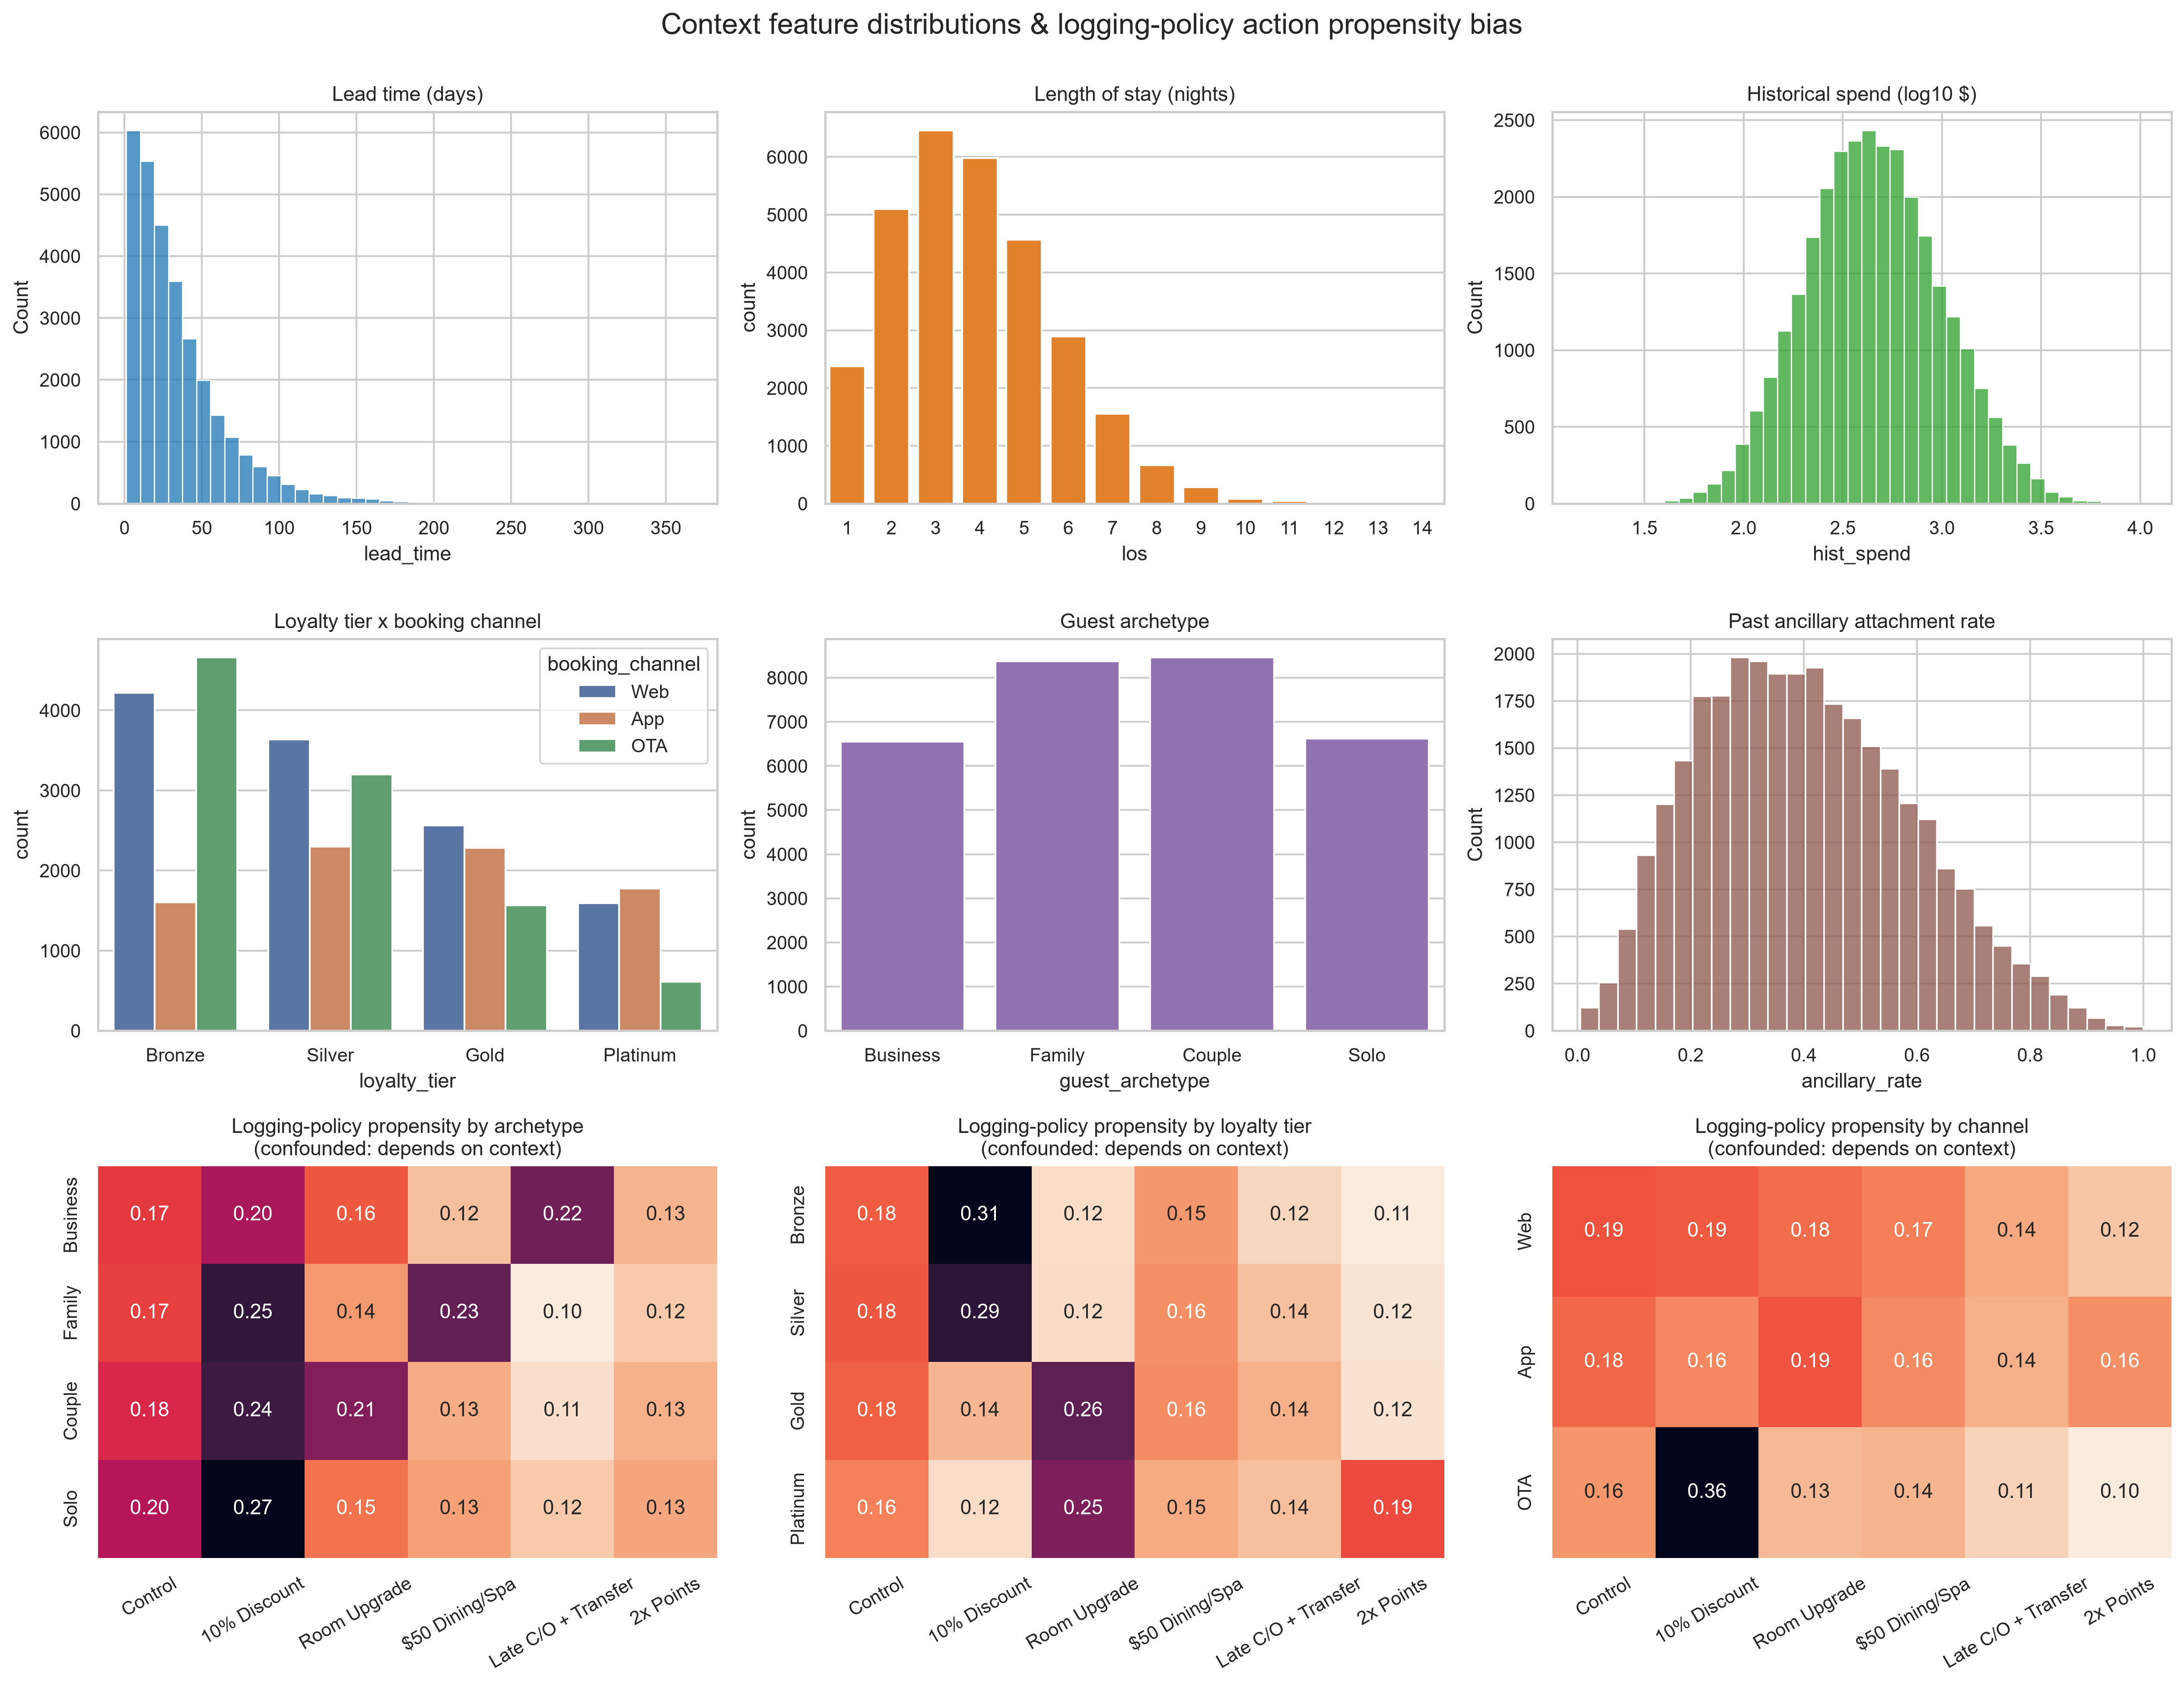

02_feature_correlations_importance.png


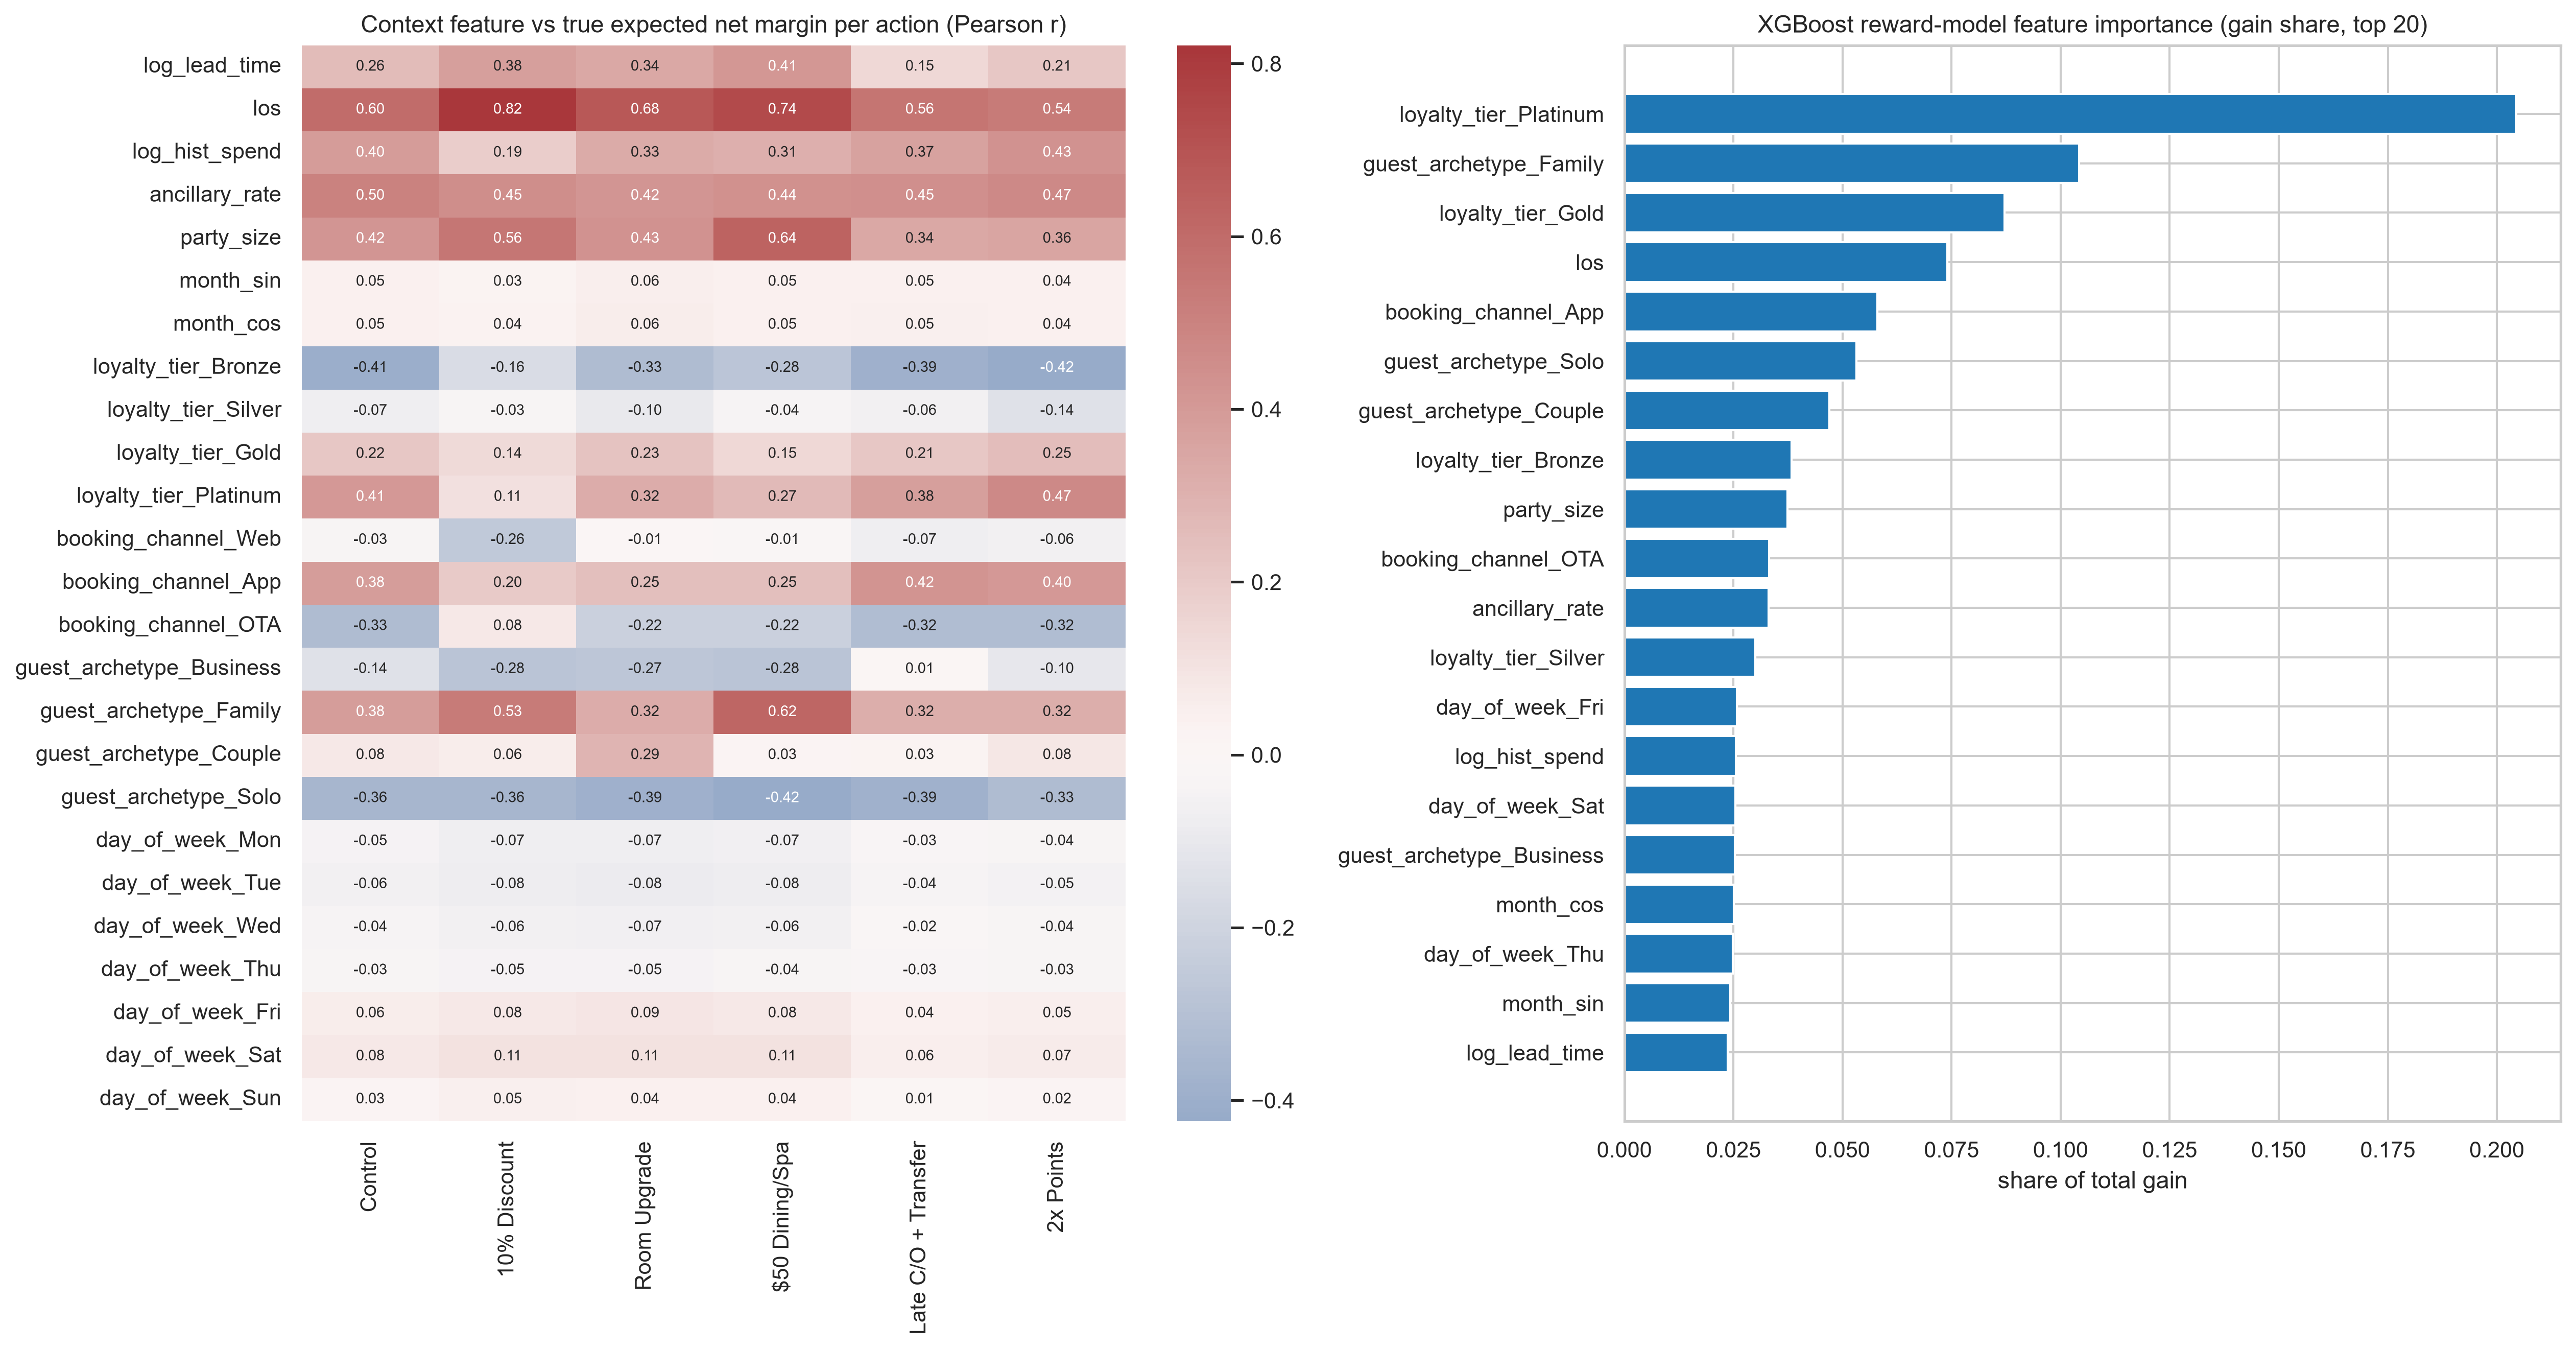

03_training_loss_curves.png


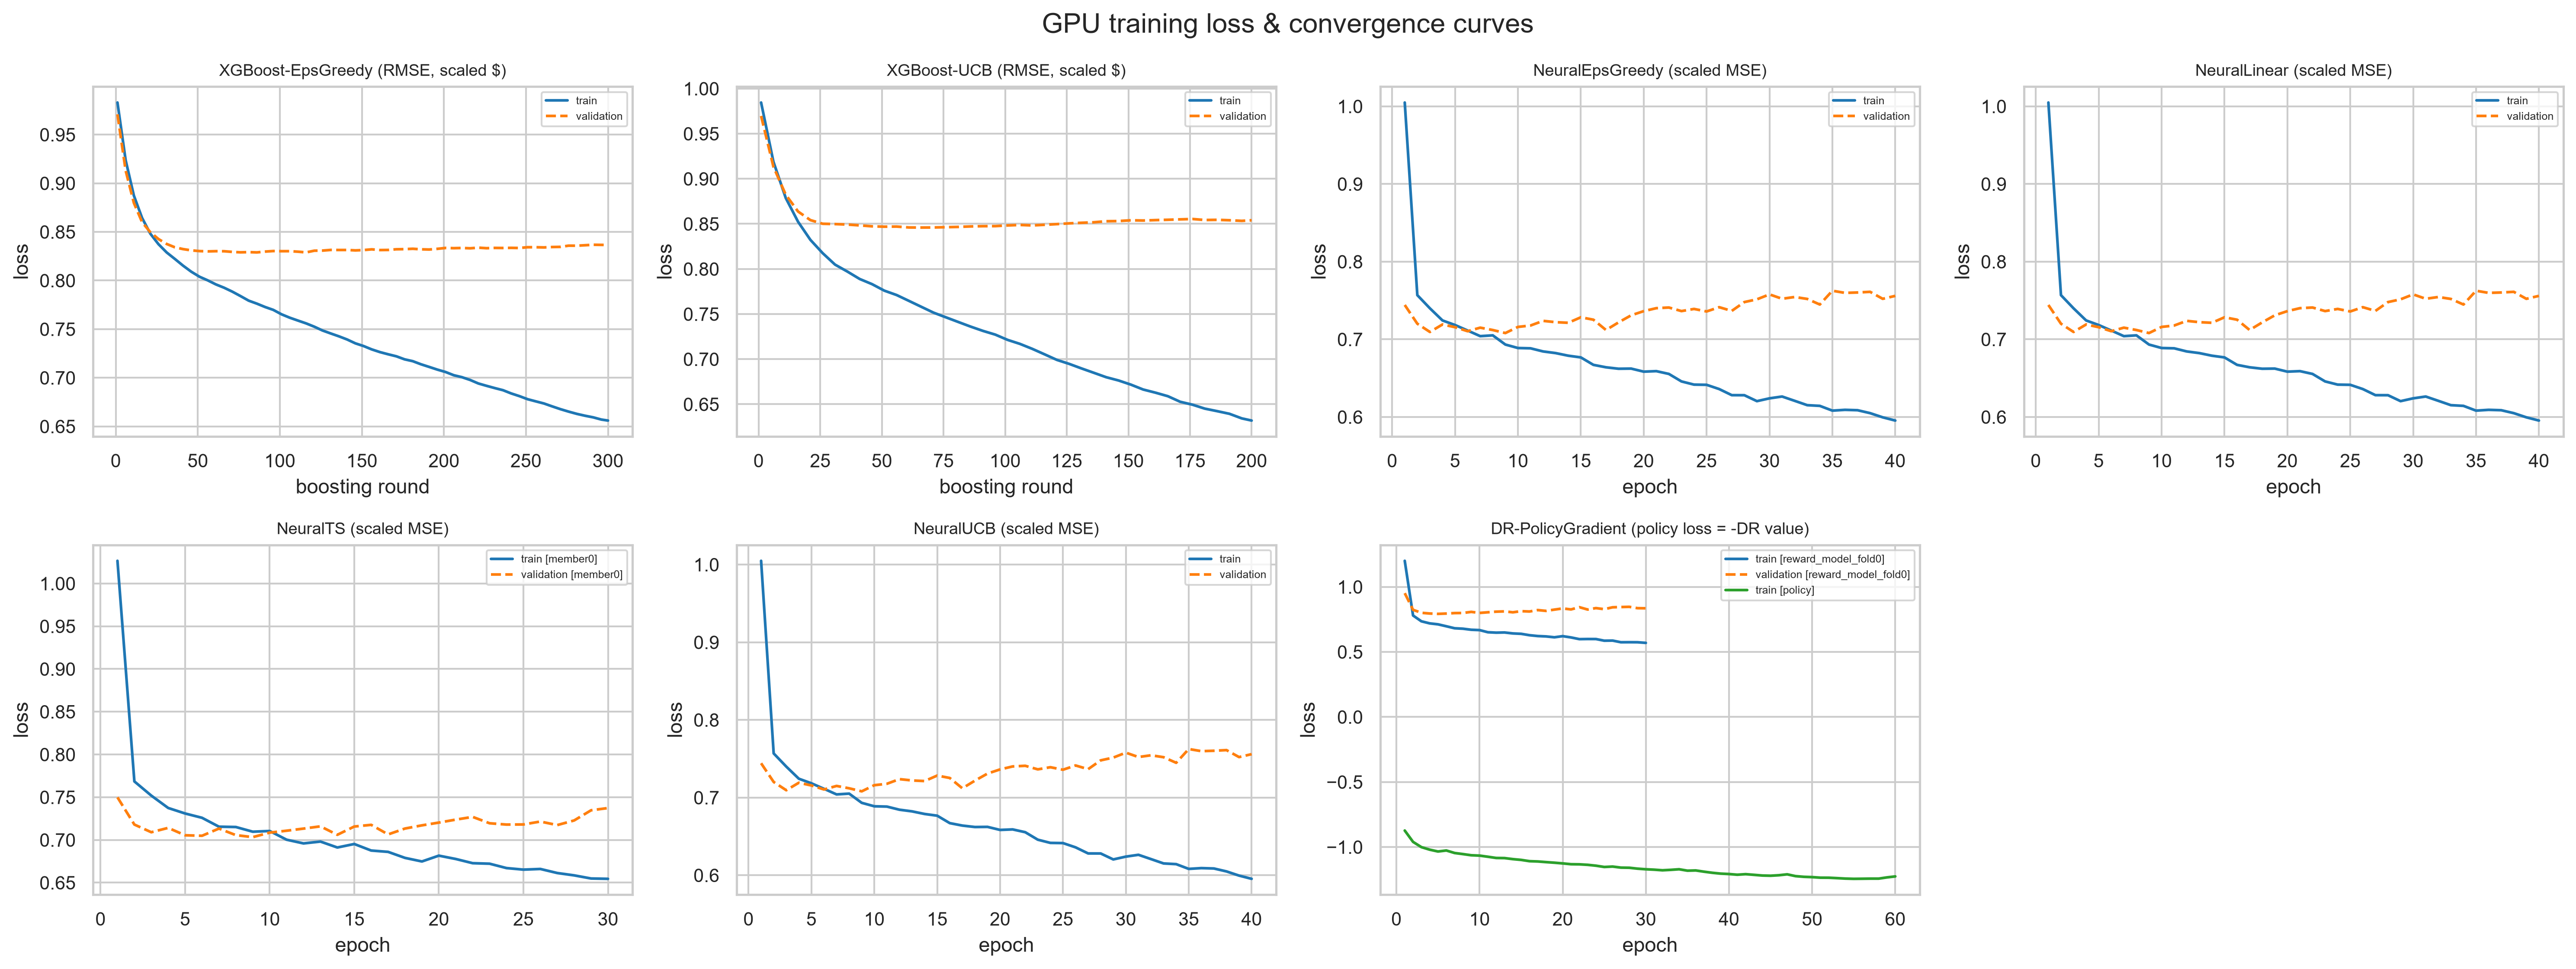

04_model_comparison_ope.png


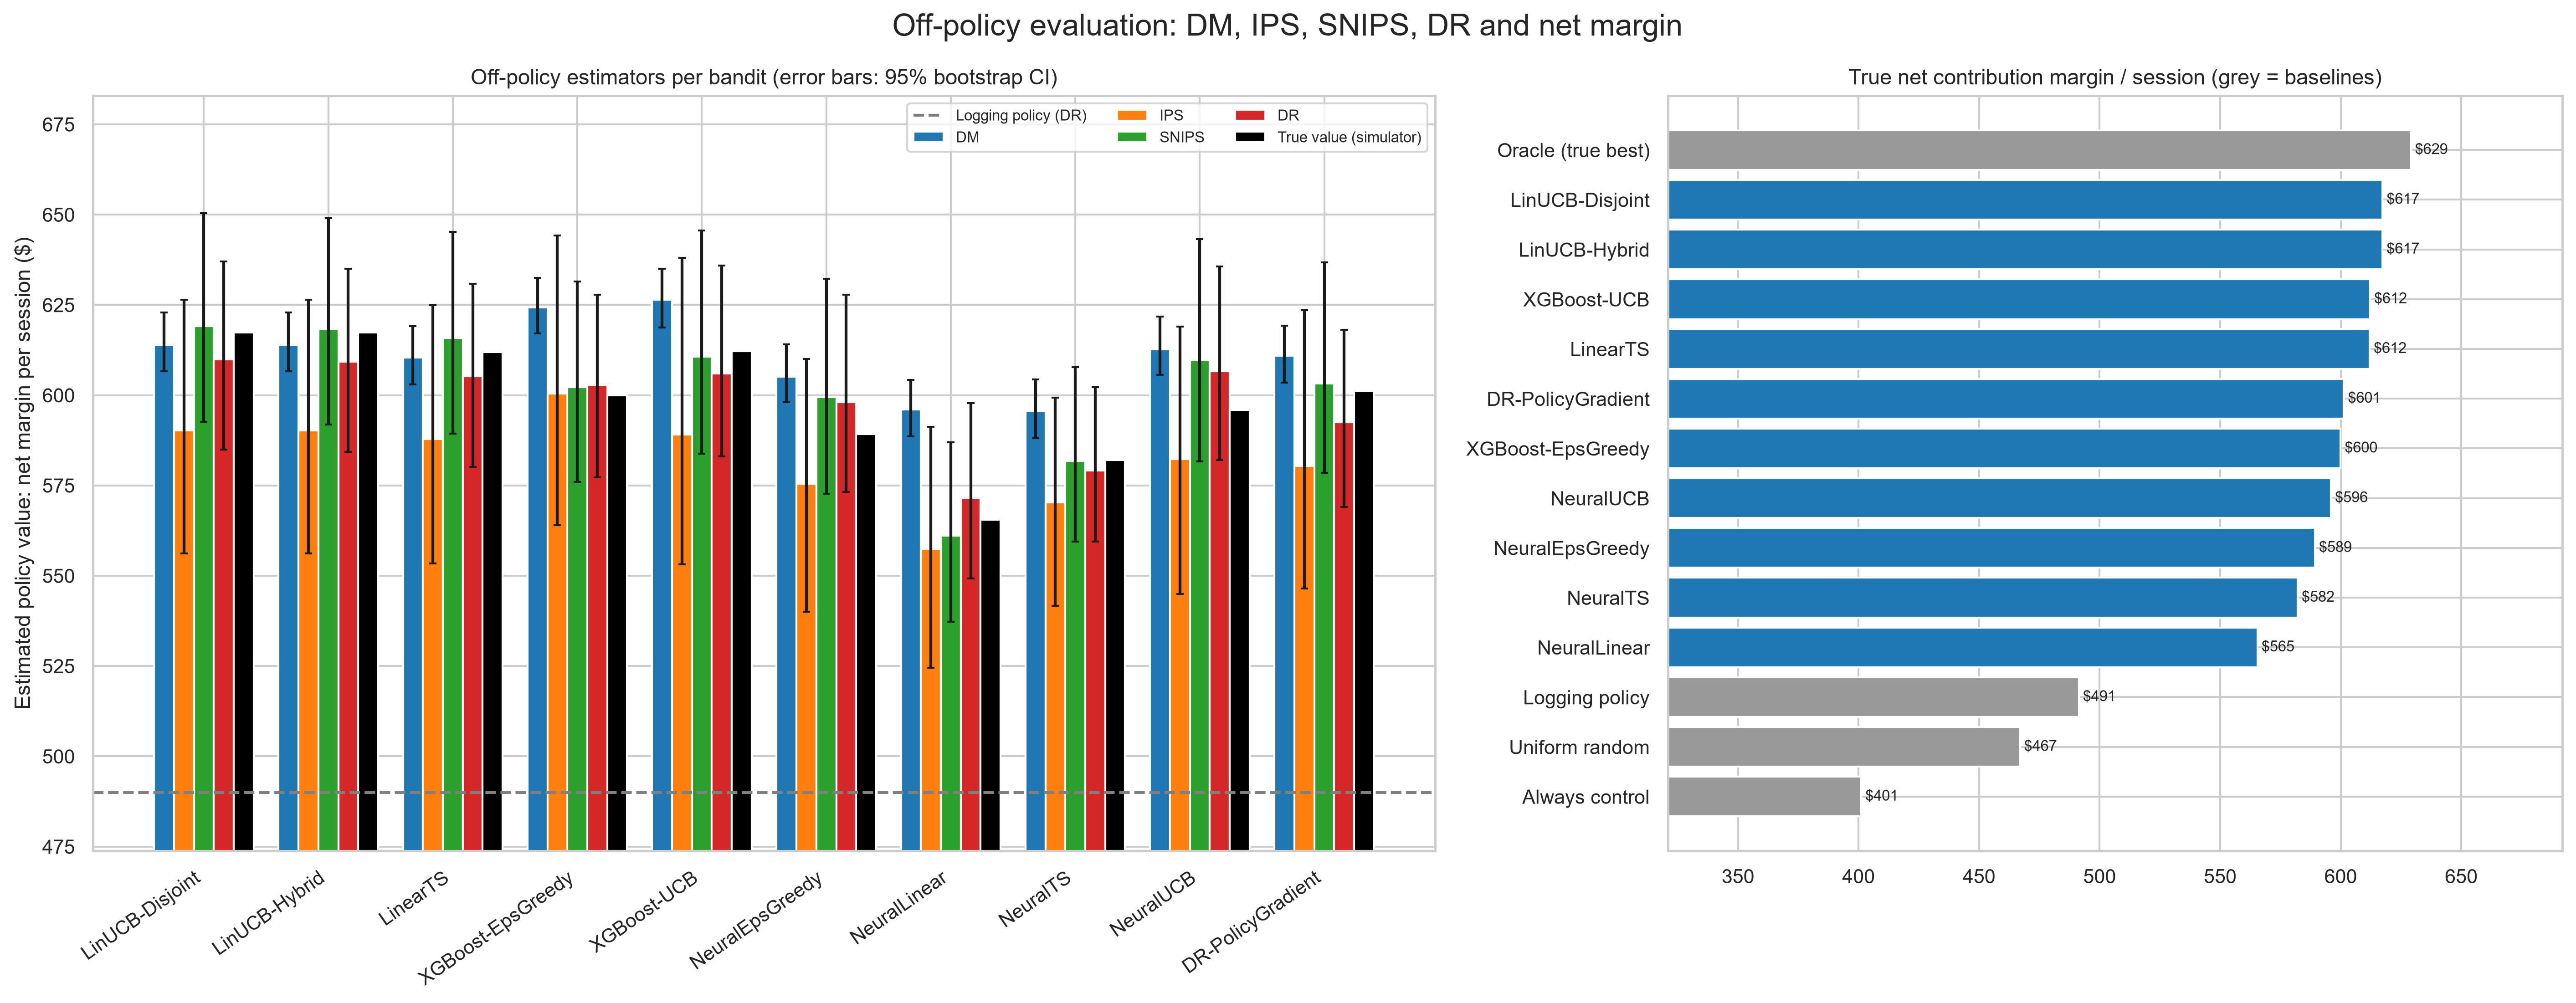

05_cumulative_regret_replay.png


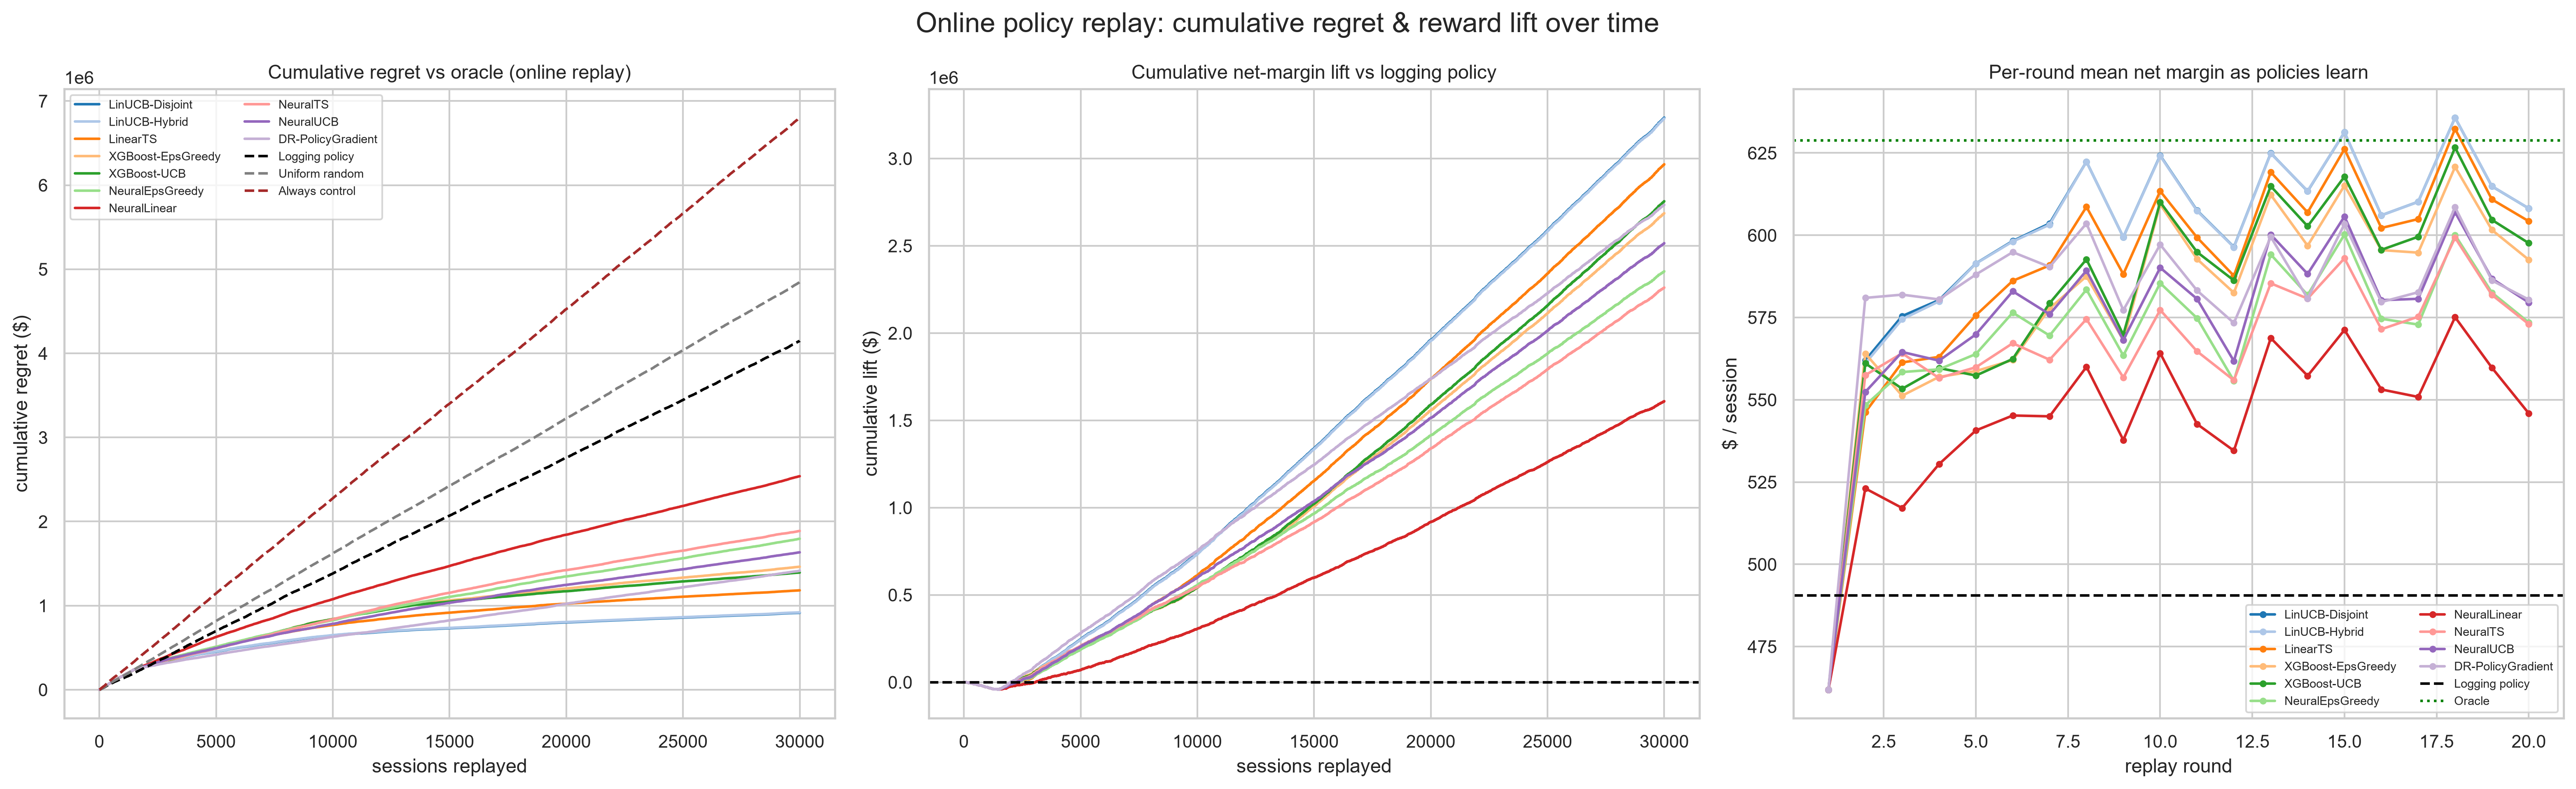

06_segment_action_heatmap.png


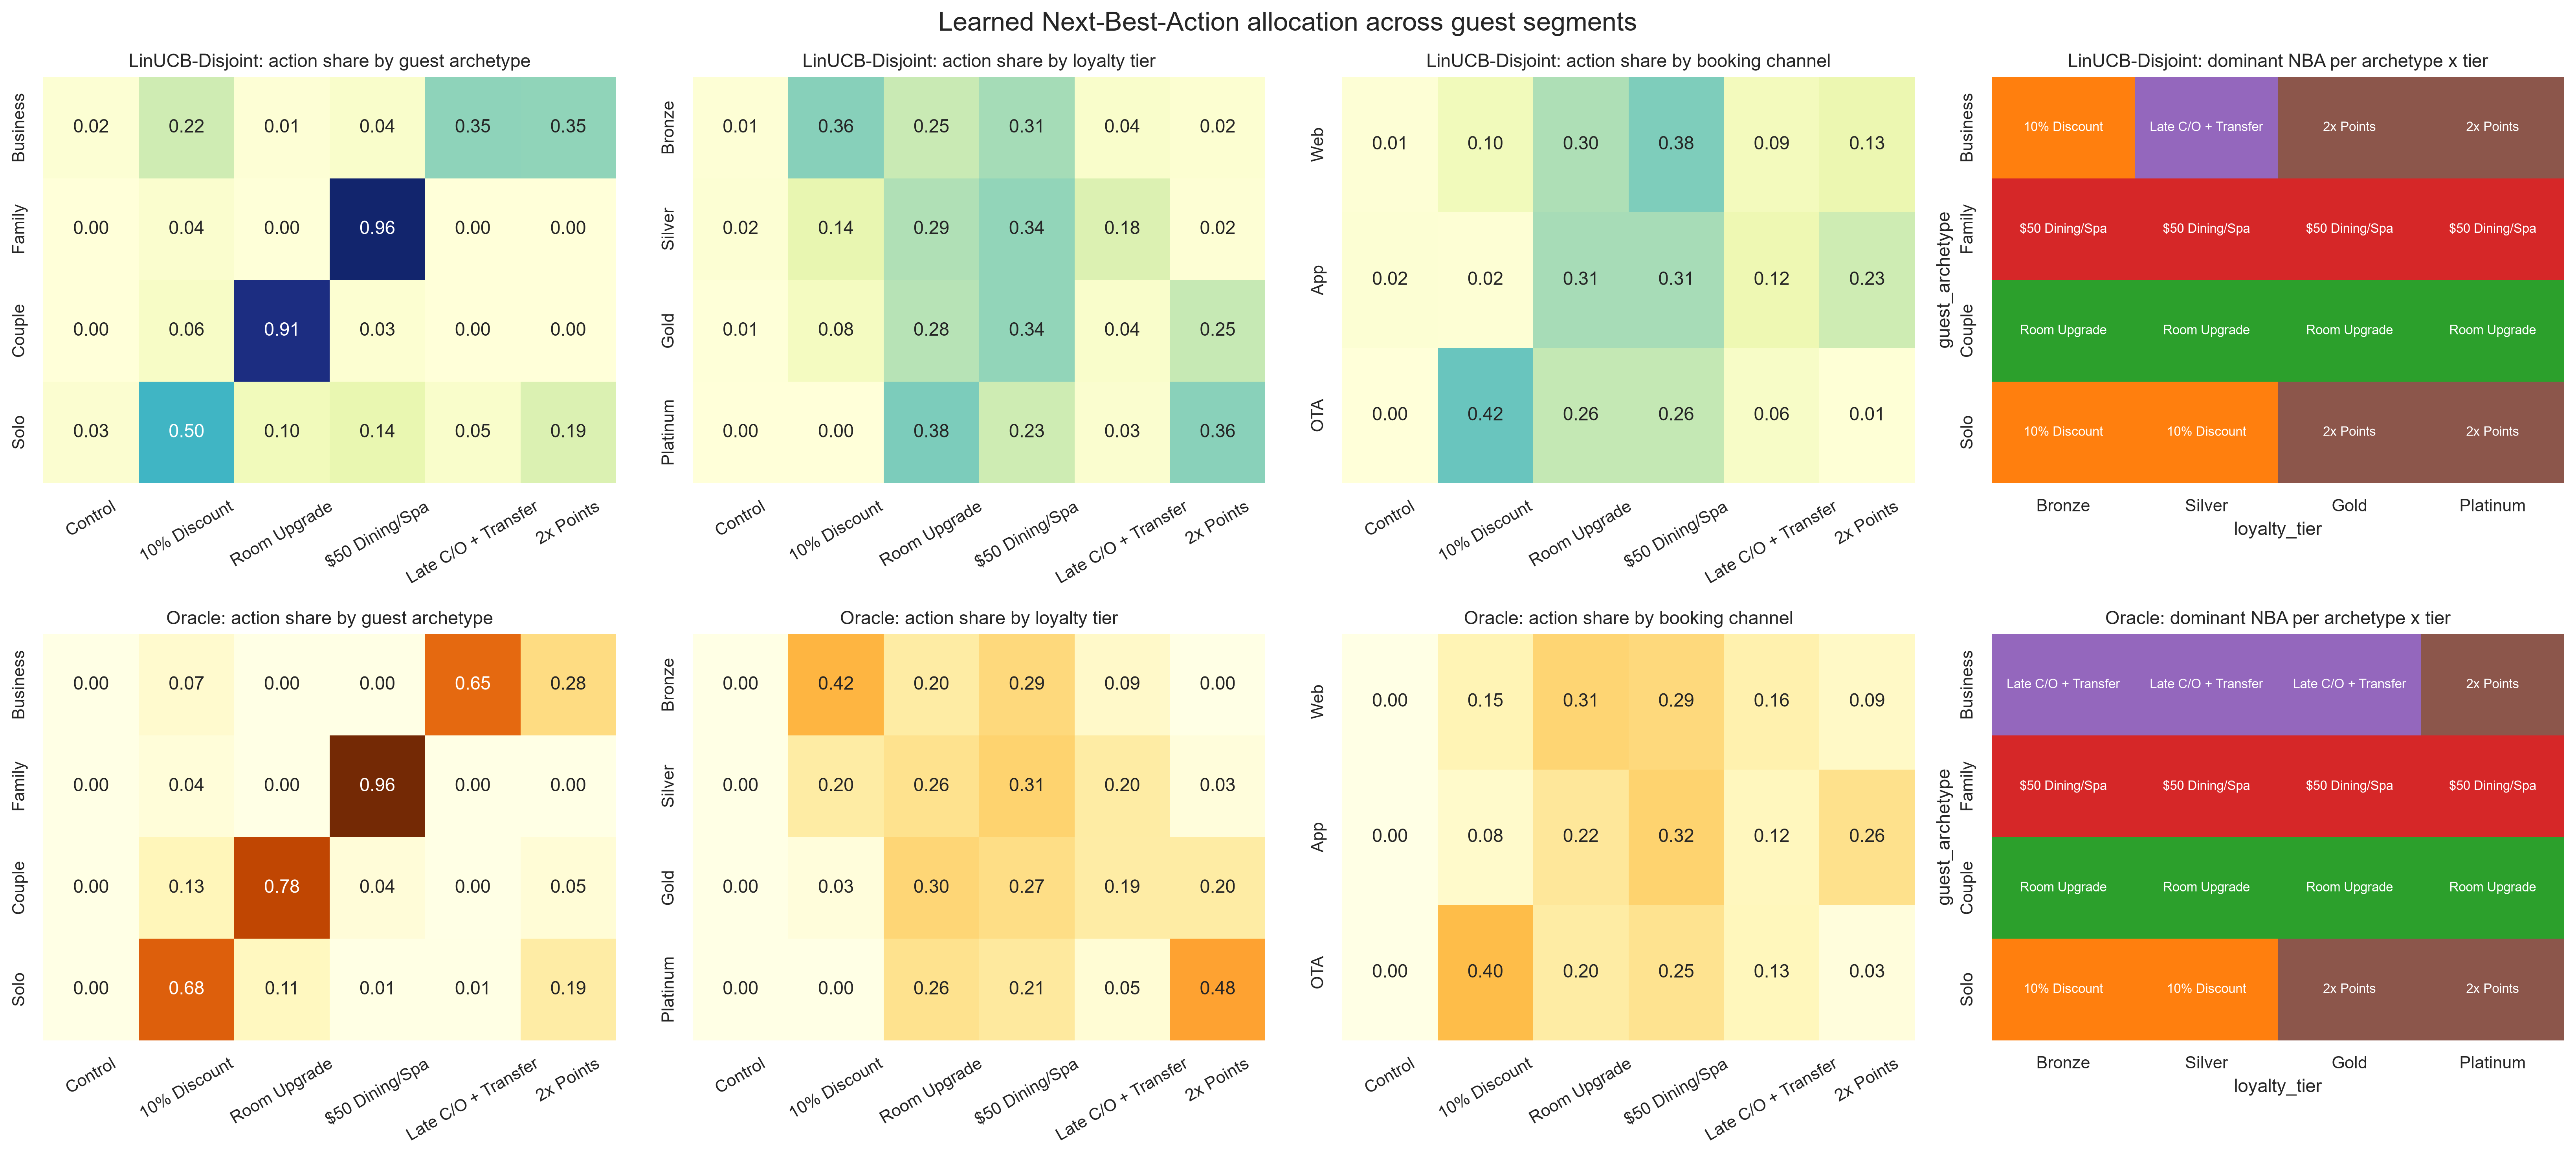

In [18]:
best = max(models, key=lambda k: results[k]["DR"])
paths = [
 plot_data_distributions(df),
 plot_correlations_importance(df, Xall, fnames, models["XGBoost-EpsGreedy"].feature_importance()),
 plot_training_curves(metrics_path),
 plot_model_comparison(results),
 plot_replay(replays),
 plot_segment_heatmap(dte, models[best].action_probs(Xte).argmax(1), best, T_te.argmax(1)),
]
for p in paths:
    print(p.name); display(Image(filename=str(p), width=1100))

### 13.6 Registry & summary

In [19]:
registry = {"best_model": best, "models": list(models), "n_features": int(Xtr.shape[1]), "n_actions": N_ACTIONS,
            "feature_names": fnames, "dr_value": {k: results[k]["DR"] for k in models},
            "true_value": {k: results[k]["TRUE"] for k in models}}
(MODELS_DIR / "model_registry.json").write_text(json.dumps(registry, indent=2))
log_jsonl(metrics_path, {"event": "pipeline_done", "best_model": best, "entry": "notebook"})
print(f"best model by DR: {best} (DR=${results[best]['DR']:.1f}, true=${results[best]['TRUE']:.1f}, "
      f"logging=${results['Logging policy']['TRUE']:.1f}, oracle=${results['Oracle (true best)']['TRUE']:.1f})")
m2 = load_model(MODELS_DIR, best)
print("reload max |diff| of scores:", float(np.abs(m2.mean_scores(Xte[:100]) - models[best].mean_scores(Xte[:100])).max()))

best model by DR: LinUCB-Disjoint (DR=$609.9, true=$617.3, logging=$491.3, oracle=$629.1)
reload max |diff| of scores: 0.0
